# Fase 3C — RoBERTuito (IroSvA) — v5

**Nested CV 5×3 agrupada · Optuna TPE (20 trials) · F1-Macro**

Versión alineada con BETO y DistilBETO: mismo preprocesamiento, mismo protocolo y mismo espacio de búsqueda.

RoBERTuito recibe el train oficial preprocesado por `01_preprocesamiento_dl_transformers.ipynb` (sin retirar registros en función del test) y se limita a:

- verificar el manifest;
- construir sus `GROUP_ID` propios;
- ejecutar `StratifiedGroupKFold` 5×3;
- optimizar con F1-Macro;
- guardar checkpoints, curvas y resultados por Outer Fold.

No elimina filas utilizando el test oficial.

Los tres Transformers reciben **el mismo texto**, `MESSAGE_TRANSFORMER`, generado con el preprocesamiento oficial de Pérez et al. (2022) (`pysentimiento.preprocessing.preprocess_tweet`).

**Versión v4.** Entrenamiento revisado a partir del diagnóstico de convergencia (solo train): learning rate ∈ {1e-5, 2e-5}, label smoothing 0.1, decaimiento del LR por capas 0.9, early stopping con paciencia 2 y refit con el mismo scheduler que la búsqueda. Los Inner Folds no guardan checkpoints. Resultados en carpetas `_v4`; la v3 queda intacta.

### Qué cambia en la v5 respecto a la v4

Cambios decididos con los pilotos v5b (rondas 1–3), que usaron **solo el train oficial**; el test no intervino en ninguna decisión.

| Cambio | Motivo (evidencia) |
|---|---|
| `dropout_interno` ∈ {0.1, 0.2} en la búsqueda | P12: subir el dropout oculto y de atención a 0.2 redujo la brecha train–validación (−0.06 a −0.10) sin bajar el F1 más de 0.01 en los 6 casos |
| `congelar_frac` ∈ {0, 0.25} en la búsqueda (embeddings + 25 % inferior del encoder) | P1: no bajó el F1 en ningún caso y redujo la brecha en BETO y DistilBETO |
| LR = 2e-5, épocas máx. = 6 y `loss_mode` = balanced **fijos** | Elegidos en 45/45, 44/45 y 37/45 Outer Folds de la v4 |
| Warmup = 0, **explícito** | En transformers 5 `warmup_ratio` ya no existe y la v4 lo descartaba en silencio (la v4 corrió sin warmup). P9 mostró que el warmup del 10 % no cambia nada; se mantiene 0 por continuidad y ahora se declara |
| `argumentos_entrenamiento()` ya no descarta argumentos en silencio | Hallazgo de la auditoría (warmup perdido) |
| Métricas `nll` y `ece` **sin pesos de clase** | Auditoría: la "pérdida de validación" de la v4 estaba ponderada por clase |
| Diagnóstico 16-bis con train **completo**, NLL y temperatura | Auditoría (submuestra de train) y calibración |
| Test: además de `prob_ironia`, `prob_ironia_calibrada` con temperatura ajustada **solo con el train** | Pilotos: T ≈ 1.2–1.75 (sobreconfianza); el temperature scaling reduce el ECE sin cambiar el F1 |

Descartadas en los pilotos: R-Drop, EMA, Mixout, LoRA, quitar los pesos de clase, entrenar solo el último tercio del encoder (con o sin dropout) y combinar congelar + dropout fuera de la búsqueda.

Resultados en carpetas `_v5` nuevas: la v4 queda intacta. **El test oficial sigue bloqueado** (`EJECUTAR_TEST_OFICIAL = False`); será su tercera evaluación (v3, v4, v5), lo que debe declararse en la tesis.


### Revisión antes de la corrida larga

Esta versión mantiene las correcciones de robustez ya incorporadas:

1. (v4) los Inner Folds no guardan checkpoints: si se interrumpe uno, se repite completo (~30 s); el refit y el test sí se reanudan desde la última época;
2. los trials interrumpidos de Optuna se cierran mediante la API pública `Study.tell(..., FAIL)`;
3. la historia de entrenamiento se congela antes de evaluaciones posteriores para no alterar curvas ni `best_epoch`;
4. el preprocesamiento no retira registros del train en función del test; las coincidencias train ↔ test se reportan solo en la evaluación final, como análisis de sensibilidad;
5. BETO, DistilBETO y RoBERTuito verifican el mismo manifest y reciben el mismo texto, pero construyen grupos y folds propios;
6. si `MESSAGE_TRANSFORMER` está vacío (preprocesamiento ejecutado sin `pysentimiento`), la carga se detiene.
7. (v4) label smoothing 0.1 (solo en la pérdida de entrenamiento), LR decay por capas 0.9, LR ∈ {1e-5, 2e-5}, batch 16, épocas máximas ∈ {4, 6}, early stopping con paciencia 2;
8. (v4) el refit y el test entrenan con el scheduler de `num_train_epochs` (máximo) y se detienen en la época elegida (`DetenerEnEpoca`), igual que en los Inner Folds.

### Estructura de checkpoints

Todos los Transformers usan la misma organización compacta para Windows:

```text
seguimiento/
└── r5x3t20_v4/
    └── completo/
        ├── ckpt/
        ├── state/
        ├── curves/
        ├── graphs/
        ├── audit/
        └── tmp/
```

Un ejemplo de Inner Fold queda:

```text
ckpt/mx/outer1/refit/checkpoint-...   (v4: solo refit y test guardan checkpoints)
```

Codificación de la configuración:

- `P`: texto común `MESSAGE_TRANSFORMER` (preprocesamiento de pysentimiento)
- `l1` / `l2`: learning rate `1e-5` / `2e-5`
- `b16`: batch size 16
- `e4` / `e6`: máximo 4 / 6 épocas
- `w1` / `w10`: weight decay `0.01` / `0.1`
- `s` / `b`: standard / balanced loss
- `d1` / `d2` / `d3`: `classifier_dropout=0.1/0.2/0.3`
- `s1`: label smoothing `0.1`
- `r9`: LR decay por capas `0.9`

Los archivos `state` y `curves` quedan fuera de la carpeta pesada de checkpoints, de modo que los checkpoints ya completados pueden borrarse sin perder resultados ni curvas.

## 1. Librerías y entorno

En la terminal del proyecto (mismo entorno que usa Jupyter):

```powershell
py -m uv add torch transformers accelerate optuna scikit-learn pandas numpy ipython
```

Si ya tienes las dependencias, no necesitas reinstalarlas. Este notebook **no instala paquetes ni inicia GPU** por sí solo al abrirlo.

In [1]:
import os
import re

# Declarar antes de importar Transformers/Hugging Face para ocultar barras de descarga.
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("WANDB_DISABLED", "true")

import gc
import time
import json
import pickle
import html
import random
import tempfile
import shutil
import inspect
import warnings
from pathlib import Path
from datetime import datetime
from contextlib import redirect_stdout, redirect_stderr

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import optuna

from torch.utils.data import Dataset, Subset
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
)
from IPython.display import display, HTML

import matplotlib

matplotlib.use("Agg")  # Evita abrir una ventana por gráfica durante cientos de fits.
import matplotlib.pyplot as plt

import transformers
from transformers import (
    AutoTokenizer,
    AutoConfig,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    TrainerCallback,
    EarlyStoppingCallback,
    set_seed,
)
from transformers.trainer_callback import PrinterCallback, ProgressCallback
from transformers.trainer_utils import get_last_checkpoint

try:
    from huggingface_hub.utils import disable_progress_bars

    disable_progress_bars()
except (ImportError, AttributeError):
    pass
transformers.logging.set_verbosity_error()
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)

VERSIONES = {
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "optuna": optuna.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
}
print("Versiones:", " | ".join(f"{k} {v}" for k, v in VERSIONES.items()))
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))

Versiones: torch 2.14.0+cu130 | transformers 5.17.0 | optuna 5.0.0 | numpy 1.26.4 | pandas 3.0.3
CUDA: True
GPU: NVIDIA RTX 6000 Ada Generation
VRAM (GB): 48.0


## 2. Configuración

In [2]:
MODEL_NAME = "pysentimiento/robertuito-base-uncased"

DATA_DIR = Path("../data/transformers")
RESULTS_DIR = Path("../data/resultados_robertuito_grouped_5x3_tpe20_v5")
PROGRESS_DIR = RESULTS_DIR / "seguimiento"

TEXT_COLS = {"PYSENTIMIENTO": "MESSAGE_TRANSFORMER"}
LABEL_COL = "IS_IRONIC"
ID_COL = "ID"
ORIGINAL_COL = "MESSAGE"
GROUP_COL = "GROUP_ID"

MAX_LENGTH = 128
SEED = 42

# ------------------------------------------------------------
# "prueba" valida rápidamente todo el pipeline.
# "completo" = experimento definitivo 5×3 / TPE20.
# ------------------------------------------------------------
MODO = "completo"  # primero "prueba"; luego "completo" y reiniciar kernel

if MODO == "prueba":
    VARIANTES = ["mx"]
    N_OUTER = 2
    N_INNER = 2
    N_TRIALS = 2
    N_STARTUP_TRIALS = 1
elif MODO == "completo":
    VARIANTES = ["mx", "es", "cu"]
    N_OUTER = 5
    N_INNER = 3
    N_TRIALS = 20
    N_STARTUP_TRIALS = 5
else:
    raise ValueError("MODO debe ser 'prueba' o 'completo'.")

# RUN_TAG corto + subcarpetas compactas para Windows.
# v5: carpeta nueva (regularización elegida con los pilotos v5b; la v4 queda intacta).
RUN_TAG = "r5x3t20_v5"
RUN_DIR = PROGRESS_DIR / RUN_TAG / MODO
TMP_DIR = RUN_DIR / "tmp"
CHECKPOINT_DIR = RUN_DIR / "ckpt"
FIT_STATE_DIR = RUN_DIR / "state"
CURVE_DIR = RUN_DIR / "curves"
GRAPH_DIR = RUN_DIR / "graphs"
AUDIT_DIR = RUN_DIR / "audit"

for carpeta in [
    RESULTS_DIR,
    PROGRESS_DIR,
    RUN_DIR,
    TMP_DIR,
    CHECKPOINT_DIR,
    FIT_STATE_DIR,
    CURVE_DIR,
    GRAPH_DIR,
    AUDIT_DIR,
]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Flujo recomendado (sección 18): opcionalmente una corrida corta con MODO="prueba";
# luego MODO="completo". Nested CV y optimización final usan solo train y corren seguidas;
# el test oficial requiere además CONFIRMACION_TEST.
EJECUTAR_NESTED = True
EJECUTAR_OPTIMIZACION_FINAL = True  # solo train; se ejecuta tras la Nested CV
EJECUTAR_TEST_OFICIAL = False
CONFIRMACION_TEST = ""

SEMILLAS_FINALES = [42, 52, 62, 72, 82]
CLEAN_COMPLETED_CHECKPOINTS = True

# Seguimiento: panel de progreso común a todos los notebooks de modelos.
NOMBRE_EXPERIMENTO = "RoBERTuito"
HEARTBEAT_SEGUNDOS = 30
# Pitido de Windows al terminar o detenerse una etapa larga (False para desactivarlo).
AVISO_SONORO = True

# Optuna TPE: 5 trials iniciales aleatorios y 15 adaptativos en modo completo.
# Espacio común a BETO, DistilBETO y RoBERTuito.
SEARCH_SPACE = {
    "preprocessing": ["PYSENTIMIENTO"],
    "learning_rate": [2e-5],  # fijo: elegido en 45/45 Outer Folds de la v4
    "batch_size": [16],  # fijo: pilotos B y C
    "num_train_epochs": [6],  # fijo: máximo elegido en 44/45 Outer Folds; decide el early stopping
    "weight_decay": [0.01, 0.1],
    "loss_mode": ["balanced"],  # fijo: elegido en 37/45 Outer Folds de la v4
    "classifier_dropout": [0.1, 0.2, 0.3],
    "label_smoothing": [0.1],  # fijo: piloto P3 (sin LS la NLL de validación vuelve a subir)
    "lr_decay": [0.9],  # fijo (piloto B)
    # v5 — nuevas dimensiones (pilotos v5b, rondas 2 y 3):
    "dropout_interno": [0.1, 0.2],  # hidden + attention dropout; 0.1 = valor por defecto (P12)
    "congelar_frac": [0.0, 0.25],  # fracción inferior del encoder (+ embeddings) congelada (P1)
}

# Warmup EXPLÍCITO. En transformers 5.x `warmup_ratio` ya no existe y la v4 lo descartaba en
# silencio (la v4 corrió sin warmup). El piloto P9 mostró que el warmup del 10 % no cambia el F1
# ni la NLL, así que la v5 mantiene 0.0 por continuidad con la v4, ahora declarado y verificado.
WARMUP_FRACCION = 0.0

# Early stopping de los Inner Folds: épocas sin mejora de F1 antes de detener.
PACIENCIA_EARLY_STOPPING = 2

SEARCH_SPACE_REQUERIDO = {
    "preprocessing",
    "learning_rate",
    "batch_size",
    "num_train_epochs",
    "weight_decay",
    "loss_mode",
    "classifier_dropout",
    "label_smoothing",
    "lr_decay",
    "dropout_interno",
    "congelar_frac",
}
faltantes_search_space = SEARCH_SPACE_REQUERIDO - set(SEARCH_SPACE)
if faltantes_search_space:
    raise KeyError(f"SEARCH_SPACE incompleto. Faltan: {sorted(faltantes_search_space)}")

USE_BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
USE_FP16 = torch.cuda.is_available() and not USE_BF16

if torch.cuda.is_available():
    torch.set_float32_matmul_precision("high")

fits_teoricos = len(VARIANTES) * N_OUTER * (N_TRIALS * N_INNER + 1)

print(f"[CONFIG][RoBERTuito] modo={MODO} | variantes={VARIANTES}")
print(
    f"[CONFIG][RoBERTuito] Nested={N_OUTER}×{N_INNER} | "
    f"trials={N_TRIALS} | startup={N_STARTUP_TRIALS}"
)
print(
    f"[CONFIG][RoBERTuito] fine-tunings teóricos={fits_teoricos} | "
    f"nested_activo={EJECUTAR_NESTED}"
)
print(f"[CONFIG][RoBERTuito] RUN_DIR={RUN_DIR.resolve()}")
print("[CONFIG][RoBERTuito] SEARCH_SPACE OK:", sorted(SEARCH_SPACE))

# Comprobación preventiva de longitud de ruta en Windows (peor caso del espacio).
_ruta_ckpt_ejemplo = (
    CHECKPOINT_DIR / "mx" / "outer1" / "P_l2_b16_e6_w10_b_d3_s1_r9_i2_c25" / "inner3" / "checkpoint-99999"
).resolve()

print(
    f"[CONFIG][RoBERTuito] longitud ruta checkpoint ejemplo="
    f"{len(str(_ruta_ckpt_ejemplo))} caracteres"
)

if os.name == "nt" and len(str(_ruta_ckpt_ejemplo)) >= 230:
    raise RuntimeError(
        "La ruta prevista para checkpoints sigue siendo demasiado larga en Windows. "
        "Mueve el repositorio a una ruta más corta antes de entrenar."
    )

[CONFIG][RoBERTuito] modo=completo | variantes=['mx', 'es', 'cu']
[CONFIG][RoBERTuito] Nested=5×3 | trials=20 | startup=5
[CONFIG][RoBERTuito] fine-tunings teóricos=915 | nested_activo=True
[CONFIG][RoBERTuito] RUN_DIR=C:\Users\i21304\Documents\DeteccionDeSarcasmo\data\resultados_robertuito_grouped_5x3_tpe20_v5\seguimiento\r5x3t20_v5\completo
[CONFIG][RoBERTuito] SEARCH_SPACE OK: ['batch_size', 'classifier_dropout', 'congelar_frac', 'dropout_interno', 'label_smoothing', 'learning_rate', 'loss_mode', 'lr_decay', 'num_train_epochs', 'preprocessing', 'weight_decay']
[CONFIG][RoBERTuito] longitud ruta checkpoint ejemplo=198 caracteres


## 3. Carga del train y verificación del preprocesamiento

BETO, DistilBETO y RoBERTuito consumen los mismos CSV finales.

Antes de construir grupos se verifica:

- manifest del preprocesamiento y versión del pipeline;
- número final de registros por variante;
- IDs únicos;
- etiquetas binarias;
- `MESSAGE_TRANSFORMER` no vacío.

Este notebook no retira registros del train en función del test.

In [3]:
MANIFEST_PATH = DATA_DIR / "manifest_preprocesamiento_transformers.csv"
PIPELINE_VERSION_ESPERADA = "transformers_comun_v2"


def cargar_manifest_preprocesamiento():
    if not MANIFEST_PATH.exists():
        raise FileNotFoundError(
            f"Falta {MANIFEST_PATH}. Ejecuta primero "
            "`01_preprocesamiento_dl_transformers.ipynb`."
        )

    manifest = pd.read_csv(MANIFEST_PATH)

    requeridas = {"pipeline_version", "variante", "train_final"}
    faltantes = requeridas - set(manifest.columns)
    if faltantes:
        raise ValueError(f"Manifest incompleto; faltan columnas: {sorted(faltantes)}")

    versiones = set(manifest["pipeline_version"].astype(str))
    if versiones != {PIPELINE_VERSION_ESPERADA}:
        raise ValueError(
            f"Versión de preprocessing inesperada: {versiones}. "
            f"Se esperaba {PIPELINE_VERSION_ESPERADA}."
        )

    return manifest


MANIFEST_PREPROCESAMIENTO = cargar_manifest_preprocesamiento()


def validar_archivo_train_con_manifest(variante):
    ruta = DATA_DIR / f"train_transformers_{variante}.csv"
    if not ruta.exists():
        raise FileNotFoundError(f"Falta {ruta}. Ejecuta primero el preprocessing Transformer.")

    fila = MANIFEST_PREPROCESAMIENTO[MANIFEST_PREPROCESAMIENTO["variante"].astype(str) == variante]
    if len(fila) != 1:
        raise ValueError(f"{variante}: se esperaba exactamente una fila en el manifest.")

    return ruta, fila.iloc[0]


def cargar_train(variante):
    ruta, manifest_row = validar_archivo_train_con_manifest(variante)
    df = pd.read_csv(ruta)

    requeridas = [ID_COL, ORIGINAL_COL, LABEL_COL, *TEXT_COLS.values()]
    faltantes = [c for c in requeridas if c not in df.columns]
    if faltantes:
        raise ValueError(f"{variante}: faltan columnas {faltantes}")

    df[ID_COL] = df[ID_COL].astype(str)
    df[LABEL_COL] = df[LABEL_COL].astype(int)

    for col in [ORIGINAL_COL, *TEXT_COLS.values()]:
        df[col] = df[col].fillna("").astype(str)

    if df[ID_COL].duplicated().any():
        raise ValueError(f"{variante}: IDs duplicados en el train FINAL.")

    if not set(df[LABEL_COL].unique()).issubset({0, 1}):
        raise ValueError(f"{variante}: etiquetas fuera de 0/1.")

    vacios = {
        col: int(df[col].eq("").sum())
        for col in [ORIGINAL_COL, *TEXT_COLS.values()]
        if df[col].eq("").any()
    }
    if vacios:
        raise ValueError(
            f"{variante}: entradas vacías en el train final {vacios}. "
            "Vuelve a ejecutar `01_preprocesamiento_dl_transformers.ipynb` "
            "(MESSAGE_TRANSFORMER requiere `pysentimiento` instalado)."
        )

    esperado = int(manifest_row["train_final"])
    if len(df) != esperado:
        raise ValueError(f"{variante}: train={len(df)} pero manifest={esperado}.")

    return df.reset_index(drop=True)


for variante in ["mx", "es", "cu"]:
    tmp = cargar_train(variante)
    print(
        f"[DATA][RoBERTuito][{variante.upper()}] "
        f"n={len(tmp)} | "
        f"clases={tmp[LABEL_COL].value_counts().sort_index().to_dict()} | "
        "manifest=OK"
    )

[DATA][RoBERTuito][MX] n=2399 | clases={0: 1599, 1: 800} | manifest=OK
[DATA][RoBERTuito][ES] n=2397 | clases={0: 1598, 1: 799} | manifest=OK
[DATA][RoBERTuito][CU] n=2400 | clases={0: 1600, 1: 800} | manifest=OK


## 4. Tokenizador oficial y datos

Se usa el **tokenizer propio de RoBERTuito** (uncased). Los tres Transformers reciben el mismo texto, `MESSAGE_TRANSFORMER`, generado con `pysentimiento.preprocessing.preprocess_tweet`. No se elimina puntuación, tildes ni stopwords. El texto se tokeniza previamente (sin usar etiquetas para crear el vocabulario) y cada partición utiliza índices del mismo dataframe. Padding dinámico por batch.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
print("Tokenizer:", tokenizer.__class__.__name__)
print("do_lower_case:", getattr(tokenizer, "do_lower_case", "gestionado por tokenizer"))
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer, pad_to_multiple_of=8 if torch.cuda.is_available() else None
)


class DatasetTokenizado(Dataset):
    def __init__(self, textos, etiquetas):
        self.encoded = tokenizer(
            [str(t) for t in textos], truncation=True, max_length=MAX_LENGTH, padding=False
        )
        self.labels = np.asarray(etiquetas, dtype=np.int64)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.encoded.items()}
        item["labels"] = int(self.labels[i])
        return item


def cache_dataset(df):
    y = df[LABEL_COL].to_numpy(dtype=np.int64)
    return {prep: DatasetTokenizado(df[col].tolist(), y) for prep, col in TEXT_COLS.items()}, y

Tokenizer: TokenizersBackend
do_lower_case: gestionado por tokenizer


### 4.1 Auditoría y construcción de `GROUP_ID`

RoBERTuito crea sus grupos **únicamente para impedir leakage entre folds** dentro del train.

Se consideran equivalentes:

- texto original;
- `MESSAGE_TRANSFORMER`;
- secuencia tokenizada de `MESSAGE_TRANSFORMER` con el tokenizer de RoBERTuito.

Los grupos son propios de RoBERTuito y no dependen de los grupos o splits de los otros modelos.

In [5]:
from collections import defaultdict


def colapsar_espacios(texto):
    return re.sub(r"\s+", " ", str(texto)).strip()


class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))
        self.rank = [0] * n

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return
        if self.rank[ra] < self.rank[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra
        if self.rank[ra] == self.rank[rb]:
            self.rank[ra] += 1


def clave_tokens(ids):
    """Representación directa de los input_ids, sin hashes."""
    return ",".join(map(str, ids))


def construir_grupos_robertuito(df, variante, tokenizador=tokenizer, max_length=MAX_LENGTH):
    """Agrupa entradas equivalentes para evitar que crucen train/validación.

    Agrupación propia del modelo: texto original, cada representación de
    entrada (TEXT_COLS) y su secuencia tokenizada (truncada a MAX_LENGTH).
    """
    trabajo = df.copy().reset_index(drop=True)
    trabajo["KEY_ORIGINAL"] = trabajo[ORIGINAL_COL].map(colapsar_espacios)
    for prep, columna in TEXT_COLS.items():
        trabajo[f"KEY_{prep}"] = trabajo[columna].map(colapsar_espacios)

    for prep, columna in TEXT_COLS.items():
        ids = tokenizador(
            trabajo[columna].astype(str).tolist(),
            truncation=True,
            max_length=max_length,
            padding=False,
        )["input_ids"]
        trabajo[f"KEY_TOK_{prep}"] = [clave_tokens(x) for x in ids]

    representaciones = ["ORIGINAL", *TEXT_COLS, *[f"TOK_{p}" for p in TEXT_COLS]]
    key_cols = [f"KEY_{r}" for r in representaciones]
    uf = UnionFind(len(trabajo))

    for col in key_cols:
        first_seen = {}
        for idx, key in enumerate(trabajo[col].tolist()):
            if not key:
                continue
            if key in first_seen:
                uf.union(idx, first_seen[key])
            else:
                first_seen[key] = idx

    componentes = defaultdict(list)
    for idx in range(len(trabajo)):
        componentes[uf.find(idx)].append(idx)

    group_ids = [None] * len(trabajo)

    componentes_ordenados = sorted(componentes.values(), key=lambda miembros: min(miembros))

    for numero_grupo, miembros in enumerate(componentes_ordenados, start=1):
        gid = f"{variante}_G{numero_grupo:04d}"
        for idx in miembros:
            group_ids[idx] = gid
    trabajo[GROUP_COL] = group_ids

    resumen = []
    for nombre, col in zip(representaciones, key_cols):
        sizes = trabajo.groupby(col).size()
        repetidos = sizes[sizes > 1]
        resumen.append(
            {
                "variante": variante,
                "representacion": nombre,
                "filas_en_repeticiones": int(trabajo[col].isin(repetidos.index).sum()),
                "grupos_repetidos": int(len(repetidos)),
            }
        )

    gstats = trabajo.groupby(GROUP_COL)[LABEL_COL].agg(["size", "nunique"])
    conflictivos = set(gstats[(gstats["size"] > 1) & (gstats["nunique"] > 1)].index)
    detalle_conflictos = trabajo[trabajo[GROUP_COL].isin(conflictivos)].copy()

    resumen = pd.DataFrame(resumen)
    resumen["n_train"] = len(trabajo)
    resumen["n_group_id"] = trabajo[GROUP_COL].nunique()
    resumen["max_group_size"] = int(trabajo.groupby(GROUP_COL).size().max())
    resumen["grupos_con_labels_mixtos"] = len(conflictivos)
    return trabajo, resumen, detalle_conflictos


TRAIN_AGRUPADO = {}
AUDITORIA_GRUPOS = []
DETALLES_CONFLICTOS = []

# Se construyen los grupos de las tres variantes antes de una corrida larga.
for variante in ["mx", "es", "cu"]:
    df_audit = cargar_train(variante)
    agrupado, resumen, conflictos = construir_grupos_robertuito(df_audit, variante)
    TRAIN_AGRUPADO[variante] = agrupado
    AUDITORIA_GRUPOS.append(resumen)
    if not conflictos.empty:
        conflictos["variante"] = variante
        DETALLES_CONFLICTOS.append(conflictos)

df_auditoria_grupos = pd.concat(AUDITORIA_GRUPOS, ignore_index=True)
df_auditoria_grupos.to_csv(RUN_DIR / "auditoria_grupos_train.csv", index=False)
display(df_auditoria_grupos)

if DETALLES_CONFLICTOS:
    df_conflictos_grupo = pd.concat(DETALLES_CONFLICTOS, ignore_index=True)
    df_conflictos_grupo.to_csv(RUN_DIR / "auditoria_grupos_labels_mixtos.csv", index=False)

for variante in ["mx", "es", "cu"]:
    df_g = TRAIN_AGRUPADO[variante]
    n_mixtos = int(df_g.groupby(GROUP_COL)[LABEL_COL].nunique().gt(1).sum())
    print(
        f"[AUDIT][RoBERTuito][{variante.upper()}] n={len(df_g)} | "
        f"groups={df_g[GROUP_COL].nunique()} | "
        f"max_group={df_g.groupby(GROUP_COL).size().max()} | labels_mixtos={n_mixtos}"
    )

    if n_mixtos > 0:
        print(
            f"  ADVERTENCIA: {n_mixtos} GROUP_ID contienen etiquetas mixtas. "
            "No es data leakage porque el grupo permanece íntegro dentro de un fold, "
            "pero representa ambigüedad/ruido de etiqueta y debe documentarse."
        )

,variante,representacion,filas_en_repeticiones,grupos_repetidos,n_train,n_group_id,max_group_size,grupos_con_labels_mixtos
0,mx,ORIGINAL,0,0,2399,2397,3,0
1,mx,PYSENTIMIENTO,0,0,2399,2397,3,0
2,mx,TOK_PYSENTIMIENTO,3,1,2399,2397,3,0
3,es,ORIGINAL,0,0,2397,2306,17,1
4,es,PYSENTIMIENTO,131,41,2397,2306,17,1
5,es,TOK_PYSENTIMIENTO,127,41,2397,2306,17,1
6,cu,ORIGINAL,6,3,2400,2397,2,0
7,cu,PYSENTIMIENTO,6,3,2400,2397,2,0
8,cu,TOK_PYSENTIMIENTO,6,3,2400,2397,2,0


[AUDIT][RoBERTuito][MX] n=2399 | groups=2397 | max_group=3 | labels_mixtos=0
[AUDIT][RoBERTuito][ES] n=2397 | groups=2306 | max_group=17 | labels_mixtos=1
  ADVERTENCIA: 1 GROUP_ID contienen etiquetas mixtas. No es data leakage porque el grupo permanece íntegro dentro de un fold, pero representa ambigüedad/ruido de etiqueta y debe documentarse.
[AUDIT][RoBERTuito][CU] n=2400 | groups=2397 | max_group=2 | labels_mixtos=0


### 4.2 Pre-flight metodológico

El pre-flight valida el train final y los grupos de RoBERTuito.

No accede al test para eliminar o decidir registros.

In [6]:
def comprobar_preflight_robertuito():
    print("=" * 78)
    print("PRE-FLIGHT — ROBERTUITO GROUPED NESTED CV")
    print("=" * 78)

    if MODO == "completo":
        esperado = (N_OUTER, N_INNER, N_TRIALS, N_STARTUP_TRIALS)

        if esperado != (5, 3, 20, 5):
            raise ValueError(
                f"Configuración inesperada: {esperado}; " "se esperaba 5×3, 20 trials, startup=5."
            )

    if not torch.cuda.is_available():
        raise RuntimeError(
            "CUDA no disponible. Verifica entorno/PyTorch antes de entrenar RoBERTuito."
        )

    for variante in ["mx", "es", "cu"]:
        _, manifest_row = validar_archivo_train_con_manifest(variante)

        df = TRAIN_AGRUPADO[variante]

        if len(df) != int(manifest_row["train_final"]):
            raise ValueError(f"{variante}: train agrupado no coincide " "con el manifest.")

        if df[ID_COL].duplicated().any():
            raise ValueError(f"{variante}: IDs duplicados.")

        if df[GROUP_COL].isna().any():
            raise ValueError(f"{variante}: GROUP_ID nulo.")

        if not set(df[LABEL_COL].unique()).issubset({0, 1}):
            raise ValueError(f"{variante}: etiquetas fuera de 0/1.")

        n_mixtos = int(df.groupby(GROUP_COL)[LABEL_COL].nunique().gt(1).sum())

        if n_mixtos:
            print(
                f"[AUDIT][RoBERTuito][{variante.upper()}] "
                f"ADVERTENCIA: {n_mixtos} GROUP_ID "
                "con etiquetas mixtas; se documentan "
                "como ruido/ambigüedad."
            )

    print("Preprocessing:", PIPELINE_VERSION_ESPERADA)
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"Nested: {N_OUTER}×{N_INNER} | Optuna={N_TRIALS} | startup={N_STARTUP_TRIALS}")
    print("Train final:", {v: len(TRAIN_AGRUPADO[v]) for v in ["mx", "es", "cu"]})
    print("PRE-FLIGHT DE DATOS: OK")


comprobar_preflight_robertuito()

PRE-FLIGHT — ROBERTUITO GROUPED NESTED CV
[AUDIT][RoBERTuito][ES] ADVERTENCIA: 1 GROUP_ID con etiquetas mixtas; se documentan como ruido/ambigüedad.
Preprocessing: transformers_comun_v2
GPU: NVIDIA RTX 6000 Ada Generation
Nested: 5×3 | Optuna=20 | startup=5
Train final: {'mx': 2399, 'es': 2397, 'cu': 2400}
PRE-FLIGHT DE DATOS: OK


## 5. Métricas, pesos de clase y modelos independientes

En cada Inner Fold la pérdida balanceada calcula pesos **solo** con el train de ese fold. Cada llamada `crear_modelo()` carga RoBERTuito desde cero con nueva cabeza de clasificación binaria. Los mensajes de pesos `MISSING`/`UNEXPECTED` quedan en un log, no en Jupyter.

**v4.** `ClasificadorTrainer` aplica label smoothing solo durante el entrenamiento (la pérdida de validación sigue siendo entropía cruzada estándar) y un learning rate decreciente por capas: la cabeza usa el LR base y cada capa inferior lo multiplica por 0.9. `ParadaTemprana` hace early stopping sin guardar checkpoints y `DetenerEnEpoca` detiene el refit en la época elegida sin alterar el scheduler.

In [7]:
def establecer_semilla(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    set_seed(seed)


def liberar_memoria():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def softmax_np(logits):
    z = np.asarray(logits, dtype=np.float64)
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def nll_binaria(probs, labels):
    """NLL estándar: SIN pesos de clase y SIN label smoothing (auditoría v5)."""
    labels = np.asarray(labels, dtype=int)
    return float(-np.mean(np.log(np.clip(probs[np.arange(len(labels)), labels], 1e-12, 1.0))))


def ece_binaria(probs, labels, n_bins=10):
    """ECE con 10 bins de igual masa sobre la confianza de la clase predicha."""
    labels = np.asarray(labels, dtype=int)
    conf = probs.max(axis=1)
    acierto = (probs.argmax(axis=1) == labels).astype(float)
    grupos = np.array_split(np.argsort(conf, kind="stable"), n_bins)
    return float(sum(len(g) / len(conf) * abs(acierto[g].mean() - conf[g].mean())
                     for g in grupos if len(g)))


def metricas(prediction):
    logits, labels = prediction
    if isinstance(logits, tuple):
        logits = logits[0]
    y_pred = np.asarray(logits).argmax(axis=-1)
    probs = softmax_np(logits)
    return {
        "nll": nll_binaria(probs, labels),
        "ece": ece_binaria(probs, labels),
        "f1_macro": f1_score(labels, y_pred, average="macro"),
        "accuracy": accuracy_score(labels, y_pred),
        "precision_macro": precision_score(labels, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(labels, y_pred, average="macro", zero_division=0),
    }


def pesos_balanceados(y):
    classes = np.array([0, 1])
    w = compute_class_weight("balanced", classes=classes, y=np.asarray(y))
    return torch.tensor(w, dtype=torch.float32)


PATRON_CAPA = re.compile(r"\.layer\.(\d+)\.")


def congelar_fraccion_inferior(model, fraccion):
    """v5: congela embeddings + la fracción inferior de capas del encoder (piloto P1)."""
    if not fraccion:
        return []
    n_total = 1 + max(int(m.group(1)) for n, _ in model.named_parameters()
                      if (m := PATRON_CAPA.search(n)))
    n_congeladas = max(1, round(n_total * float(fraccion)))
    capas = set()
    for nombre, p in model.named_parameters():
        m = PATRON_CAPA.search(nombre)
        if "embeddings" in nombre or (m and int(m.group(1)) < n_congeladas):
            p.requires_grad = False
            if m:
                capas.add(int(m.group(1)))
    return sorted(capas)


def crear_modelo(seed, classifier_dropout=0.2, cfg=None):
    """v5: `cfg` aporta `dropout_interno` (piloto P12) y `congelar_frac` (piloto P1)."""
    cfg = cfg or {}
    establecer_semilla(seed)
    with (RUN_DIR / "carga_modelos.log").open("a", encoding="utf-8") as log, redirect_stdout(
        log
    ), redirect_stderr(log):
        config = AutoConfig.from_pretrained(MODEL_NAME, num_labels=2)
        if config.model_type != "roberta":
            raise ValueError(f"Se esperaba arquitectura RoBERTa, recibida: {config.model_type}")
        # RoBERTa: dropout de la cabeza de clasificación.
        config.classifier_dropout = float(classifier_dropout)
        # v5: dropout interno (oculto y de atención) del encoder y los embeddings.
        dropout_interno = float(cfg.get("dropout_interno", getattr(config, "hidden_dropout_prob")))
        config.hidden_dropout_prob = dropout_interno
        config.attention_probs_dropout_prob = dropout_interno
        model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, config=config)
    congelar_fraccion_inferior(model, cfg.get("congelar_frac", 0.0))
    return model


class ClasificadorTrainer(Trainer):
    """v4: pérdida ponderada opcional + label smoothing (solo en train) + LR decay por capas."""

    def __init__(self, *args, class_weights=None, label_smoothing=0.0, lr_decay=1.0, **kwargs):
        self.class_weights = class_weights
        self.label_smoothing = float(label_smoothing)
        self.lr_decay = float(lr_decay)
        super().__init__(*args, **kwargs)

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs["labels"]
        outputs = model(**{k: v for k, v in inputs.items() if k != "labels"})
        weights = (
            self.class_weights.to(outputs.logits.device) if self.class_weights is not None else None
        )
        # Smoothing SOLO al entrenar: la pérdida de validación sigue siendo entropía cruzada estándar.
        ls = self.label_smoothing if model.training else 0.0
        loss = F.cross_entropy(outputs.logits, labels, weight=weights, label_smoothing=ls)
        return (loss, outputs) if return_outputs else loss

    def create_optimizer(self, *args, **kwargs):
        if self.optimizer is not None:
            return self.optimizer
        if self.lr_decay >= 1.0:
            return super().create_optimizer(*args, **kwargs)
        # Capas: BERT/RoBERTa `encoder.layer.N`, DistilBERT `transformer.layer.N`.
        patron = re.compile(r"\.layer\.(\d+)\.")
        n_capas = 1 + max(
            int(m.group(1)) for n, _ in self.model.named_parameters() if (m := patron.search(n))
        )
        base_lr, wd = self.args.learning_rate, self.args.weight_decay
        grupos = {}
        for nombre, p in self.model.named_parameters():
            if not p.requires_grad:
                continue
            m = patron.search(nombre)
            if m:
                profundidad = n_capas - int(m.group(1))  # última capa = 1
            elif "embeddings" in nombre:
                profundidad = n_capas + 1  # embeddings = LR más bajo
            else:
                profundidad = 0  # cabeza de clasificación / pooler = LR base
            sin_wd = nombre.endswith("bias") or "LayerNorm" in nombre or "layer_norm" in nombre
            clave = (base_lr * self.lr_decay**profundidad, 0.0 if sin_wd else wd)
            grupos.setdefault(clave, []).append(p)
        self.optimizer = torch.optim.AdamW(
            [{"params": ps, "lr": lr, "weight_decay": w} for (lr, w), ps in grupos.items()]
        )
        return self.optimizer


class ParadaTemprana(TrainerCallback):
    """Early stopping por F1-Macro de validación sin guardar checkpoints (Inner Folds)."""

    def __init__(self, paciencia=2):
        self.paciencia, self.mejor, self.sin_mejora = int(paciencia), -np.inf, 0

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        f1 = (metrics or {}).get("eval_f1_macro")
        if f1 is None:
            return control
        if f1 > self.mejor:
            self.mejor, self.sin_mejora = f1, 0
        else:
            self.sin_mejora += 1
            if self.sin_mejora >= self.paciencia:
                control.should_training_stop = True
        return control


class DetenerEnEpoca(TrainerCallback):
    """Refit/test con el MISMO scheduler que la búsqueda: se detiene en la época elegida."""

    def __init__(self, epocas):
        self.epocas = int(epocas)

    def on_epoch_end(self, args, state, control, **kwargs):
        if state.epoch is not None and state.epoch >= self.epocas - 1e-6:
            control.should_training_stop = True
        return control


## 6. Argumentos de entrenamiento

El Trainer evalúa por época con AdamW + 10% warmup. En los **Inner Folds** no se guardan checkpoints: los modelos internos se descartan y el F1 y la mejor época se leen de la curva; `ParadaTemprana` detiene el entrenamiento si el F1-Macro no mejora durante `PACIENCIA_EARLY_STOPPING` épocas. En el **refit externo y final no hay early stopping** (no se puede usar el Outer Test ni el test oficial como validación): se entrena con el scheduler de `num_train_epochs` y `DetenerEnEpoca` corta en la mediana de las mejores épocas internas.

In [8]:
def argumentos_entrenamiento(carpeta, cfg, seed, con_validacion=True, epochs=None):
    params = {
        "output_dir": str(carpeta),
        "learning_rate": cfg["learning_rate"],
        "per_device_train_batch_size": cfg["batch_size"],
        "per_device_eval_batch_size": cfg["batch_size"],
        "num_train_epochs": epochs if epochs is not None else cfg["num_train_epochs"],
        "weight_decay": cfg["weight_decay"],
        "optim": "adamw_torch",
        # Trainer recoge loss por época en state.log_history;
        # PrinterCallback se elimina para no saturar VS Code.
        "logging_strategy": "epoch",
        "save_strategy": "epoch",  # Inner y refit: reinicio desde última época completa.
        "load_best_model_at_end": bool(con_validacion),
        "save_total_limit": 2,  # último + mejor (si son diferentes)
        "save_only_model": False,  # Estado optimizer/scheduler requerido para reanudar.
        "report_to": "none",
        "disable_tqdm": True,
        # Necesario para que EarlyStoppingCallback conserve su contador
        # al reanudar desde un checkpoint.
        "restore_callback_states_from_checkpoint": True,
        "dataloader_num_workers": 0,
        "seed": seed,
        "data_seed": seed,
        "bf16": USE_BF16,
        "fp16": USE_FP16,
    }
    if con_validacion:
        # v4 — Inner Folds sin checkpoints: el modelo interno se descarta y F1/mejor época
        # se leen de la curva. El early stopping lo hace ParadaTemprana.
        params.update({"save_strategy": "no", "load_best_model_at_end": False})
    sig = inspect.signature(TrainingArguments.__init__).parameters
    if "eval_strategy" in sig:
        params["eval_strategy"] = "epoch" if con_validacion else "no"
    elif "evaluation_strategy" in sig:
        params["evaluation_strategy"] = "epoch" if con_validacion else "no"
    else:
        raise RuntimeError("Esta versión de Transformers no admite evaluación por época.")
    # v5: warmup explícito (transformers 5: `warmup_steps` acepta una fracción en [0, 1)).
    if "warmup_ratio" in sig:
        params["warmup_ratio"] = float(WARMUP_FRACCION)
    else:
        params["warmup_steps"] = float(WARMUP_FRACCION)
    # v5: nunca descartar argumentos en silencio (así se perdió el warmup de la v4).
    descartados = sorted(k for k in params if k not in sig)
    if descartados:
        raise RuntimeError(f"TrainingArguments no acepta {descartados} en esta versión de transformers.")
    return TrainingArguments(**params)


def mejor_epoca(trainer, max_epochs):
    evaluaciones = [x for x in trainer.state.log_history if "eval_f1_macro" in x and "epoch" in x]
    if not evaluaciones:
        raise RuntimeError("No se encontró F1 de validación por época.")
    mejor = max(evaluaciones, key=lambda x: x["eval_f1_macro"])
    return int(np.clip(round(float(mejor["epoch"])), 1, max_epochs))


def predecir(trainer, dataset):
    logits = trainer.predict(dataset).predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    return np.argmax(logits, axis=-1)

## 7. Monitor único y archivos de recuperación

El panel se actualiza sin crear cientos de outputs. Al terminar una etapa (Nested CV, optimización final o test) el panel pasa a **verde con «✅ TERMINADO»**, la barra llega al 100 %, se imprime un mensaje con la hora en la celda y suena un aviso en Windows (`AVISO_SONORO`). Si se detiene por error o interrupción, el panel pasa a **rojo con «❌ DETENIDO»**. Se registran señales en `monitor.log` aproximadamente cada 30 segundos durante los pasos de entrenamiento. Los trials completos se guardan en una base SQLite por Outer Fold y los resultados de cada Outer Fold se escriben inmediatamente en CSV.

Si un entrenamiento se interrumpe, puedes ejecutar otra vez el notebook con **los mismos CSV y la misma configuración**. Se comprueba la configuración guardada para evitar mezclar experimentos distintos.

In [9]:
class Monitor:
    """Panel único de progreso + monitor.log, con estado activo / terminado / error.

    Clase común a todos los notebooks de modelos (ML, Hard Voting y Transformers).
    """

    def __init__(self, ruta, total, ya_completados=0, unidad="Fine-tunings completados"):
        self.ruta = Path(ruta)
        self.ruta.mkdir(parents=True, exist_ok=True)
        self.log = self.ruta / "monitor.log"
        self.total = int(total)
        self.unidad = unidad
        self.completados = int(ya_completados)
        self.completados_inicio = int(ya_completados)
        self.inicio = time.monotonic()
        self.ultimo_pulso = 0
        self.etapa = "Inicializando"
        self.estado = "activo"  # activo | terminado | error
        self.handle = display(HTML(f"<b>Preparando {NOMBRE_EXPERIMENTO}...</b>"), display_id=True)
        self.mostrar(forzar=True)

    def registrar(self, msg):
        with self.log.open("a", encoding="utf-8") as f:
            f.write(f"[{datetime.now():%Y-%m-%d %H:%M:%S}] {msg}\n")

    def mostrar(self, etapa=None, forzar=False):
        if etapa is not None:
            self.etapa = str(etapa)
        ahora = time.monotonic()
        if not forzar and ahora - self.ultimo_pulso < HEARTBEAT_SEGUNDOS:
            return
        self.ultimo_pulso = ahora
        minutos = (ahora - self.inicio) / 60
        hechos_sesion = self.completados - self.completados_inicio
        faltan = max(0, self.total - self.completados)
        eta = (
            f"~{minutos / hechos_sesion * faltan:.0f} min"
            if hechos_sesion >= 2
            else "calculando..."
        )
        marca = datetime.now().strftime("%H:%M:%S")
        color, titulo = {
            "activo": ("#777", f"{NOMBRE_EXPERIMENTO} — seguimiento en vivo"),
            "terminado": ("#2e7d32", f"✅ {NOMBRE_EXPERIMENTO} — TERMINADO"),
            "error": ("#c62828", f"❌ {NOMBRE_EXPERIMENTO} — DETENIDO"),
        }[self.estado]
        grosor = 1 if self.estado == "activo" else 3
        tiempo = (
            f"Tiempo: {minutos:.1f} min | ETA orientativo: {eta}"
            if self.estado == "activo"
            else f"Duración total: {minutos:.1f} min | Finalizó a las {marca}"
        )
        panel = (
            f'<div style="font-family:system-ui;padding:12px;border:{grosor}px solid {color};'
            'border-radius:8px;max-width:800px">'
            f'<b style="color:{color}">{titulo}</b><br>'
            f"Etapa: <b>{html.escape(self.etapa)}</b><br>"
            f"{self.unidad}: {self.completados}/{self.total} "
            f"({100*self.completados/max(1,self.total):.1f}%)<br>"
            f'<progress value="{self.completados}" max="{max(1,self.total)}" '
            'style="width:100%"></progress><br>'
            f"{tiempo}<br>"
            f"Última señal: {marca}<br>Log: {html.escape(str(self.log))}</div>"
        )
        self.handle.update(HTML(panel))

    def iniciar(self, msg):
        self.registrar(msg)
        self.mostrar(etapa=msg, forzar=True)

    def pulso(self):
        if time.monotonic() - self.ultimo_pulso >= HEARTBEAT_SEGUNDOS:
            self.registrar("ACTIVO: " + self.etapa)
            self.mostrar(forzar=True)

    def fit_terminado(self, msg):
        self.completados += 1
        self.registrar(msg)
        self.mostrar(etapa=msg, forzar=True)

    def finalizar(self, msg):
        """Etapa terminada: panel verde al 100 %, mensaje en la celda y aviso sonoro."""
        self.registrar(f"FINALIZADO: {msg} ({self.completados}/{self.total} contados)")
        self.estado = "terminado"
        self.completados = max(self.completados, self.total)
        self.mostrar(etapa=msg, forzar=True)
        print(f"\n✅ [{NOMBRE_EXPERIMENTO}] {msg} — {datetime.now():%Y-%m-%d %H:%M:%S}", flush=True)
        avisar_fin(ok=True)

    def fallar(self, msg):
        """Etapa detenida (error o interrupción): panel rojo, mensaje en la celda y aviso sonoro."""
        self.registrar(f"DETENIDO: {msg}")
        self.estado = "error"
        self.mostrar(etapa=msg, forzar=True)
        print(f"\n❌ [{NOMBRE_EXPERIMENTO}] {msg} — {datetime.now():%Y-%m-%d %H:%M:%S}", flush=True)
        avisar_fin(ok=False)


def avisar_fin(ok=True):
    """Pitido de Windows al terminar (3 veces) o al detenerse (1 vez); en otros sistemas no hace nada."""
    if not AVISO_SONORO:
        return
    try:
        import winsound

        for _ in range(3 if ok else 1):
            winsound.MessageBeep(winsound.MB_ICONASTERISK if ok else winsound.MB_ICONHAND)
            time.sleep(0.5)
    except Exception:
        pass


class PulsoTrainer(TrainerCallback):
    def __init__(self, monitor):
        self.monitor = monitor

    def on_step_end(self, args, state, control, **kwargs):
        self.monitor.pulso()
        return control


def entrenador_silencioso(trainer):
    trainer.remove_callback(PrinterCallback)
    trainer.remove_callback(ProgressCallback)
    return trainer


def csv_atomico(df, ruta):
    ruta = Path(ruta)
    tmp = ruta.with_name(ruta.name + ".tmp")
    df.to_csv(tmp, index=False)
    os.replace(tmp, ruta)


def configuracion_actual():
    return {
        "checkpoint": MODEL_NAME,
        "modo": MODO,
        "variantes": VARIANTES,
        "outer": N_OUTER,
        "inner": N_INNER,
        "trials": N_TRIALS,
        "startup_trials": N_STARTUP_TRIALS,
        "semilla": SEED,
        "max_length": MAX_LENGTH,
        "search_space": SEARCH_SPACE,
        "preprocessing_pipeline": PIPELINE_VERSION_ESPERADA,
        "train_final": {
            str(fila.variante): int(fila.train_final)
            for fila in MANIFEST_PREPROCESAMIENTO.itertuples()
        },
        "group_strategy": "original_"
        + "_".join(TEXT_COLS).lower()
        + "_tokenized_connected_components_v1",
        "fixed_training": {
            "optim": "adamw_torch",
            "warmup_fraccion": WARMUP_FRACCION,
            "early_stopping_patience": PACIENCIA_EARLY_STOPPING,
            "early_stopping": "parada_temprana_f1_sin_checkpoints_v4",
            "refit_epoch_strategy": "median_inner_best_epoch_rounded_same_scheduler_v4",
            "loss": "ce_label_smoothing_train_only_v4",
            "optimizer": "adamw_layerwise_lr_decay_v4",
            "regularizacion_v5": "dropout_interno_y_congelar_frac_en_busqueda",
            "metricas_v5": "nll_y_ece_sin_pesos",
            "curvas": "train_eval_loss_epoch_csv_best_outer_png_v1",
            "checkpoint": "refit_and_test_only_v4",
        },
    }


def verificar_configuracion():
    ruta = RUN_DIR / "config_ejecucion.json"
    actual = configuracion_actual()
    if ruta.exists():
        anterior = json.loads(ruta.read_text(encoding="utf-8"))
        if anterior != actual:
            raise ValueError(
                "Esta carpeta tiene una corrida con datos/configuración diferentes. "
                "No mezcles resultados; cambia MODO/carpeta o archiva el experimento."
            )
    else:
        tmp = ruta.with_suffix(".tmp")
        tmp.write_text(json.dumps(actual, indent=2, ensure_ascii=False), encoding="utf-8")
        os.replace(tmp, ruta)


def ruta_estudio(variante, nombre):
    return RUN_DIR / f"robertuito_{variante}_{nombre}.db"


def cargar_study(variante, nombre):
    ruta = ruta_estudio(variante, nombre)
    if not ruta.exists():
        return None
    return optuna.load_study(
        study_name=f"RoBERTuito_{variante}_{nombre}",
        storage=f"sqlite:///{ruta.resolve().as_posix()}",
    )


def contar_completados():
    n = 0
    for variante in VARIANTES:
        ruta_csv = RUN_DIR / f"robertuito_detalle_{variante}.csv"
        completados = set()
        if ruta_csv.exists():
            completados = set(pd.read_csv(ruta_csv)["outer_fold"].astype(int))
        for outer in range(1, N_OUTER + 1):
            if outer in completados:
                n += N_TRIALS * N_INNER + 1
            else:
                st = cargar_study(variante, f"outer{outer}")
                if st is not None:
                    n += (
                        min(
                            N_TRIALS,
                            sum(t.state == optuna.trial.TrialState.COMPLETE for t in st.trials),
                        )
                        * N_INNER
                    )
    return n

### 7.1 Checkpoints por época y curvas de pérdida

Las carpetas de cada entrenamiento se identifican por **variante, Outer Fold, configuración exacta e Inner Fold**, no por número de trial: si Optuna debe reencolar un trial interrumpido, se pueden recuperar sus Inner Folds sin perderlos. El estado se guarda al finalizar cada época; la validación de cada entrenamiento usa solo su Inner Fold, nunca el test oficial.

Los CSV contienen `epoch`, `train_loss`, `val_loss` y `val_f1_macro`. Se generan gráficos por Outer Fold del **mejor trial según Inner CV**, con las tres particiones internas; al acabar cada variante se pueden consultar en `graphs/<variante>/`. Las épocas que no alcanzan todos los folds por early stopping se indican con `n_folds` en el CSV agregado.

In [10]:
# ==============================================================
# CHECKPOINTS, CURVAS Y REANUDACIÓN — ESQUEMA COMÚN A LOS TRES TRANSFORMERS
# ==============================================================
def config_id(cfg):
    """ID compacto y determinista para evitar rutas largas en Windows."""
    prep = {"PYSENTIMIENTO": "P"}[cfg["preprocessing"]]
    lr = int(round(float(cfg["learning_rate"]) * 1e5))  # 5e-5 -> 5
    bs = int(cfg["batch_size"])
    ep = int(cfg["num_train_epochs"])
    wd = int(round(float(cfg["weight_decay"]) * 100))  # .05 -> 5
    loss = {"standard": "s", "balanced": "b"}[cfg["loss_mode"]]
    drop = int(round(float(cfg["classifier_dropout"]) * 10))  # .2 -> 2, .3 -> 3
    ls = int(round(float(cfg.get("label_smoothing", 0.0)) * 10))  # .1 -> 1
    lrd = int(round(float(cfg.get("lr_decay", 1.0)) * 10))  # .9 -> 9
    di = int(round(float(cfg.get("dropout_interno", 0.1)) * 10))  # v5: .2 -> 2
    cf = int(round(float(cfg.get("congelar_frac", 0.0)) * 100))  # v5: .25 -> 25
    return f"{prep}_l{lr}_b{bs}_e{ep}_w{wd}_{loss}_d{drop}_s{ls}_r{lrd}_i{di}_c{cf}"


def rutas_inner_fit(variante, etiqueta, cfg, inner_fold):
    """
    Estructura común a los tres Transformers:
      ckpt/mx/outer1/S_l5_b16_e5_w5_s_d3/inner1/
      state/mx_outer1_S_l5_b16_e5_w5_s_d3_inner1_complete.json
      curves/mx_outer1_S_l5_b16_e5_w5_s_d3_inner1.csv
    """
    ident = config_id(cfg)
    base = f"{variante}_{etiqueta}_{ident}_inner{inner_fold}"
    return {
        "config_id": ident,
        "state": FIT_STATE_DIR / f"{base}_complete.json",
        "curve": CURVE_DIR / f"{base}.csv",
        "ckpt": CHECKPOINT_DIR / variante / etiqueta / ident / f"inner{inner_fold}",
    }


def cargar_estado_inner_si_completo(rutas):
    if not rutas["state"].exists():
        return None
    return json.loads(rutas["state"].read_text(encoding="utf-8"))


def json_atomico(obj, ruta):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temporal = ruta.with_name(ruta.name + ".tmp")
    temporal.write_text(json.dumps(obj, indent=2, ensure_ascii=False), encoding="utf-8")
    os.replace(temporal, ruta)


def extraer_curva(log_history):
    """Empareja train/validation por época, sin tocar Outer Test."""
    filas = {}
    for entry in log_history:
        if "epoch" not in entry:
            continue

        epoch = round(float(entry["epoch"]), 6)
        if epoch <= 0:
            continue

        fila = filas.setdefault(
            epoch,
            {"epoch": epoch, "train_loss": np.nan, "val_loss": np.nan, "val_f1_macro": np.nan},
        )

        if "loss" in entry:
            fila["train_loss"] = float(entry["loss"])
        if "eval_loss" in entry:
            fila["val_loss"] = float(entry["eval_loss"])
        if "eval_f1_macro" in entry:
            fila["val_f1_macro"] = float(entry["eval_f1_macro"])
        if "eval_nll" in entry:  # v5: NLL sin pesos de clase
            fila["val_nll"] = float(entry["eval_nll"])

    if not filas:
        return pd.DataFrame(columns=["epoch", "train_loss", "val_loss", "val_f1_macro"])

    return pd.DataFrame(list(filas.values())).sort_values("epoch").reset_index(drop=True)


def obtener_mejor_epoca_desde_curva(curva, max_epochs):
    if curva.empty or "val_f1_macro" not in curva or curva["val_f1_macro"].dropna().empty:
        return int(max_epochs)

    fila = curva.loc[curva["val_f1_macro"].idxmax()]
    return max(1, min(int(max_epochs), int(round(float(fila["epoch"])))))


def limpiar_checkpoint_dir(carpeta):
    if CLEAN_COMPLETED_CHECKPOINTS:
        shutil.rmtree(carpeta, ignore_errors=True)


def ejecutar_inner_fit_reanudable(
    cache, y, idx_train, idx_val, cfg, variante, etiqueta, inner_fold, seed_modelo, monitor=None
):
    rutas = rutas_inner_fit(variante, etiqueta, cfg, inner_fold)

    previo = cargar_estado_inner_si_completo(rutas)
    if previo is not None:
        if previo.get("config_id") != rutas["config_id"]:
            raise ValueError("Estado Inner almacenado no coincide con la configuración.")

        if monitor:
            monitor.fit_terminado(
                f"REUTILIZADO {variante.upper()} {etiqueta} "
                f"cfg={rutas['config_id']} inner={inner_fold}: "
                f"F1={float(previo['f1_inner']):.4f}"
            )

        return (float(previo["f1_inner"]), int(previo["best_epoch"]), rutas)

    rutas["ckpt"].mkdir(parents=True, exist_ok=True)

    dataset_completo = cache[cfg["preprocessing"]]
    train_ds = Subset(dataset_completo, list(map(int, idx_train)))
    val_ds = Subset(dataset_completo, list(map(int, idx_val)))

    if monitor:
        monitor.iniciar(
            f"{variante.upper()} {etiqueta} | "
            f"cfg={rutas['config_id']} | "
            f"Inner {inner_fold}/{N_INNER}"
        )

    model = crear_modelo(seed_modelo, cfg["classifier_dropout"], cfg)

    class_weights = pesos_balanceados(y[idx_train]) if cfg["loss_mode"] == "balanced" else None

    trainer = None
    try:
        args = argumentos_entrenamiento(rutas["ckpt"], cfg, seed_modelo, con_validacion=True)

        callbacks = [ParadaTemprana(PACIENCIA_EARLY_STOPPING)]

        if monitor:
            callbacks.append(PulsoTrainer(monitor))

        trainer = entrenador_silencioso(
            ClasificadorTrainer(
                model=model,
                args=args,
                train_dataset=train_ds,
                eval_dataset=val_ds,
                data_collator=data_collator,
                compute_metrics=metricas,
                callbacks=callbacks,
                class_weights=class_weights,
                label_smoothing=cfg["label_smoothing"],
                lr_decay=cfg["lr_decay"],
            )
        )

        ultimo = get_last_checkpoint(str(rutas["ckpt"]))

        if ultimo and monitor:
            monitor.registrar(f"Reanudando fit desde {ultimo}")

        trainer.train(resume_from_checkpoint=(ultimo if ultimo else None))

        # Congelar la historia de entrenamiento ANTES de cualquier evaluación extra.
        curva = extraer_curva(trainer.state.log_history)

        if curva.empty or curva["val_loss"].isna().all() or curva["train_loss"].isna().all():
            raise RuntimeError("Faltan las curvas train/validation loss.")

        csv_atomico(curva, rutas["curve"])

        best_epoch = obtener_mejor_epoca_desde_curva(curva, cfg["num_train_epochs"])

        # v4: sin checkpoints; el F1 interno es el mejor F1 de validación de la curva.
        f1 = float(curva["val_f1_macro"].max())

        json_atomico(
            {
                "status": "complete",
                "config_id": rutas["config_id"],
                "config": cfg,
                "f1_inner": f1,
                "best_epoch": int(best_epoch),
                "inner_fold": int(inner_fold),
                "seed": int(seed_modelo),
                "checkpoint_used_to_resume": ultimo,
            },
            rutas["state"],
        )

    finally:
        if trainer is not None:
            del trainer
        del model
        liberar_memoria()

    # Al acabar correctamente, borrar únicamente los
    # checkpoints pesados. El JSON y la curva quedan fuera de esa carpeta.
    limpiar_checkpoint_dir(rutas["ckpt"])

    if monitor:
        monitor.fit_terminado(
            f"{variante.upper()} {etiqueta} "
            f"cfg={rutas['config_id']} "
            f"Inner {inner_fold}: F1={f1:.4f}"
        )

    return f1, best_epoch, rutas


def graficar_mejor_trial(variante, outer_fold, cfg, n_inner, mostrar=False):
    """Usa solo curvas de Inner Validation del mejor trial."""
    etiqueta = f"outer{outer_fold}"
    curves = []

    for fold in range(1, n_inner + 1):
        ruta = rutas_inner_fit(variante, etiqueta, cfg, fold)["curve"]

        if not ruta.exists():
            raise FileNotFoundError(f"Falta curva del mejor trial: {ruta}")

        d = pd.read_csv(ruta)
        d["inner_fold"] = fold
        curves.append(d)

    todos = pd.concat(curves, ignore_index=True)

    resumen = todos.groupby("epoch", as_index=False).agg(
        train_loss=("train_loss", "mean"),
        val_loss=("val_loss", "mean"),
        train_std=("train_loss", "std"),
        val_std=("val_loss", "std"),
        val_f1_macro=("val_f1_macro", "mean"),
        n_folds=("inner_fold", "nunique"),
    )

    salida = GRAPH_DIR / variante
    salida.mkdir(parents=True, exist_ok=True)

    csv_atomico(todos, salida / f"outer{outer_fold}_inner_folds.csv")
    csv_atomico(resumen, salida / f"outer{outer_fold}_media_por_epoca.csv")

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(resumen["epoch"], resumen["train_loss"], marker="o", label="Train loss")
    ax.plot(resumen["epoch"], resumen["val_loss"], marker="o", label="Validation loss")
    ax.set(
        xlabel="Época",
        ylabel="Loss",
        title=(f"RoBERTuito {variante.upper()} — Outer {outer_fold} | mejor trial interno"),
    )
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()

    loss_png = salida / f"outer{outer_fold}_loss.png"
    fig.savefig(loss_png, dpi=160, bbox_inches="tight")
    if mostrar:
        display(fig)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(resumen["epoch"], resumen["val_f1_macro"], marker="o")
    ax.set(
        xlabel="Época",
        ylabel="F1-Macro validación",
        title=(f"RoBERTuito {variante.upper()} — Outer {outer_fold} | mejor trial interno"),
    )
    ax.grid(alpha=0.25)
    fig.tight_layout()

    f1_png = salida / f"outer{outer_fold}_f1.png"
    fig.savefig(f1_png, dpi=160, bbox_inches="tight")
    if mostrar:
        display(fig)
    plt.close(fig)

    return {
        "csv_inner": str(salida / f"outer{outer_fold}_inner_folds.csv"),
        "csv_media": str(salida / f"outer{outer_fold}_media_por_epoca.csv"),
        "loss_png": str(loss_png),
        "f1_png": str(f1_png),
    }

## 8. Búsqueda interna: TPE adaptativo con Optuna

Cada estudio (uno por Outer Fold) prueba 20 configuraciones: 5 propuestas iniciales aleatorias y hasta 15 adaptativas. Cada configuración se evalúa con **tres Inner Folds**, y la medida que se maximiza es su F1-Macro promedio. Como el refit usa la mediana de las mejores épocas internas, el Outer Test nunca determina ni las épocas ni los hiperparámetros.

Se mantiene la misma semilla de inicialización por Inner Fold entre trials para reducir ruido en la comparación (cada modelo parte del checkpoint preentrenado original).

**Espacio de búsqueda común a BETO, DistilBETO y RoBERTuito (v5):** `weight_decay` ∈ {0.01, 0.1}, `classifier_dropout` ∈ {0.1, 0.2, 0.3}, `dropout_interno` ∈ {0.1, 0.2} y `congelar_frac` ∈ {0, 0.25} (24 combinaciones). Fijos por evidencia de la v4 y de los pilotos: `learning_rate` = 2e-5, `batch_size` = 16, `num_train_epochs` (máximo) = 6, `loss_mode` = balanced, `label_smoothing` = 0.1, `lr_decay` = 0.9 y warmup = 0 (explícito).

**Recuperación:** SQLite guarda trials completos, los CSV muestran el historial y un archivo del sampler conserva su estado para continuaciones. Un trial interrumpido se vuelve a encolar con los mismos hiperparámetros: sus Inner Folds ya terminados se reutilizan y el que estaba en curso se repite completo (v4: los Inner Folds no guardan checkpoints).

In [11]:
def sugerir_config(trial):
    return {
        "preprocessing": trial.suggest_categorical("preprocessing", SEARCH_SPACE["preprocessing"]),
        "learning_rate": trial.suggest_categorical("learning_rate", SEARCH_SPACE["learning_rate"]),
        "batch_size": trial.suggest_categorical("batch_size", SEARCH_SPACE["batch_size"]),
        "num_train_epochs": trial.suggest_categorical(
            "num_train_epochs", SEARCH_SPACE["num_train_epochs"]
        ),
        "weight_decay": trial.suggest_categorical("weight_decay", SEARCH_SPACE["weight_decay"]),
        "loss_mode": trial.suggest_categorical("loss_mode", SEARCH_SPACE["loss_mode"]),
        "classifier_dropout": trial.suggest_categorical(
            "classifier_dropout", SEARCH_SPACE["classifier_dropout"]
        ),
        "label_smoothing": trial.suggest_categorical(
            "label_smoothing", SEARCH_SPACE["label_smoothing"]
        ),
        "lr_decay": trial.suggest_categorical("lr_decay", SEARCH_SPACE["lr_decay"]),
        "dropout_interno": trial.suggest_categorical(
            "dropout_interno", SEARCH_SPACE["dropout_interno"]
        ),
        "congelar_frac": trial.suggest_categorical("congelar_frac", SEARCH_SPACE["congelar_frac"]),
    }


def buscar_en_train(
    cache, y, groups, indices, variante, nombre, k_inner, n_trials, seed_cv, monitor=None
):
    indices = np.asarray(indices, dtype=int)
    y_inner = y[indices]
    groups_inner = np.asarray(groups)[indices]

    skf = StratifiedGroupKFold(n_splits=k_inner, shuffle=True, random_state=seed_cv)

    splits = list(skf.split(np.zeros(len(indices)), y_inner, groups=groups_inner))

    for numero, (idx_tr_local, idx_val_local) in enumerate(splits, start=1):
        g_tr = set(groups_inner[idx_tr_local])
        g_val = set(groups_inner[idx_val_local])

        if g_tr & g_val:
            raise AssertionError(
                f"{variante} {nombre} "
                f"Inner {numero}: GROUP_ID "
                "compartido entre train y validación."
            )

    def objetivo(trial):
        cfg = sugerir_config(trial)
        scores = []
        epocas = []

        for numero, (idx_tr_local, idx_val_local) in enumerate(splits, start=1):
            tr = indices[idx_tr_local]
            val = indices[idx_val_local]

            # La misma semilla por Inner Fold entre configuraciones
            # reduce ruido al comparar hiperparámetros.
            seed_fold = SEED + seed_cv * 100 + numero

            f1, best_epoch, _ = ejecutar_inner_fit_reanudable(
                cache=cache,
                y=y,
                idx_train=tr,
                idx_val=val,
                cfg=cfg,
                variante=variante,
                etiqueta=nombre,
                inner_fold=numero,
                seed_modelo=seed_fold,
                monitor=monitor,
            )

            scores.append(float(f1))
            epocas.append(int(best_epoch))

        trial.set_user_attr("f1_inner_std", float(np.std(scores, ddof=1)))
        trial.set_user_attr("best_epochs_inner", [int(e) for e in epocas])
        trial.set_user_attr(
            "refit_epochs", int(np.clip(round(np.median(epocas)), 1, cfg["num_train_epochs"]))
        )

        return float(np.mean(scores))

    sampler_file = RUN_DIR / f"sampler_{variante}_{nombre}.pkl"

    if sampler_file.exists():
        with sampler_file.open("rb") as f:
            sampler = pickle.load(f)
    else:
        sampler = optuna.samplers.TPESampler(seed=seed_cv, n_startup_trials=N_STARTUP_TRIALS)

    study = optuna.create_study(
        direction="maximize",
        sampler=sampler,
        study_name=(f"RoBERTuito_{variante}_{nombre}"),
        storage=(f"sqlite:///{ruta_estudio(variante, nombre).resolve().as_posix()}"),
        load_if_exists=True,
    )

    # Recuperar trials huérfanos tras una interrupción.
    running = [t for t in study.trials if t.state == optuna.trial.TrialState.RUNNING]

    waiting = [t for t in study.trials if t.state == optuna.trial.TrialState.WAITING]

    done = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]

    for interrumpido in running:
        ya_reencolado = any(
            (
                t.state == optuna.trial.TrialState.WAITING
                and t.system_attrs.get("fixed_params", {}) == interrumpido.params
            )
            or (t.state == optuna.trial.TrialState.COMPLETE and t.params == interrumpido.params)
            for t in waiting + done
        )

        if not ya_reencolado and interrumpido.params:
            study.enqueue_trial(interrumpido.params)

        try:
            study.tell(
                interrumpido.number, state=(optuna.trial.TrialState.FAIL), skip_if_finished=True
            )
        except (ValueError, RuntimeError) as exc:
            raise RuntimeError(
                "No se pudo cerrar el trial " f"interrumpido {interrumpido.number}."
            ) from exc

        if monitor:
            monitor.registrar(f"Trial interrumpido {interrumpido.number} " "reencolado.")

    # Un trial FAIL con estado/curva/checkpoint parcial se reencola.
    for anterior in list(study.trials):
        if anterior.state != optuna.trial.TrialState.FAIL or not anterior.params:
            continue

        tiene_avance = False

        for numero in range(1, k_inner + 1):
            rutas = rutas_inner_fit(variante, nombre, anterior.params, numero)

            if rutas["state"].exists() or get_last_checkpoint(str(rutas["ckpt"])) is not None:
                tiene_avance = True
                break

        if not tiene_avance:
            continue

        ya_pendiente_o_completo = any(
            (t.state == optuna.trial.TrialState.COMPLETE and t.params == anterior.params)
            or (
                t.state == optuna.trial.TrialState.WAITING
                and t.system_attrs.get("fixed_params", {}) == anterior.params
            )
            for t in study.trials
        )

        if not ya_pendiente_o_completo:
            study.enqueue_trial(anterior.params)

            if monitor:
                monitor.registrar(f"Reencolado trial FAIL {anterior.number} con " "avance parcial.")

    completos = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)

    faltantes = max(0, n_trials - completos)

    if monitor and completos:
        monitor.registrar(
            f"Recuperados {completos} trials de {variante} {nombre}; faltan {faltantes}."
        )

    def trial_finalizado(st, trial):
        tmp_sampler = sampler_file.with_suffix(".pkl.tmp")

        with tmp_sampler.open("wb") as f:
            pickle.dump(st.sampler, f)

        os.replace(tmp_sampler, sampler_file)

        csv_atomico(st.trials_dataframe(), RUN_DIR / f"trials_{variante}_{nombre}.csv")

        n_completos = sum(t.state == optuna.trial.TrialState.COMPLETE for t in st.trials)

        if trial.state == optuna.trial.TrialState.COMPLETE:
            msg = (
                f"{variante.upper()} {nombre} | "
                f"trial {n_completos}/{n_trials} "
                f"F1_inner={trial.value:.4f} | "
                f"mejor={st.best_value:.4f}"
            )
        else:
            msg = f"{variante.upper()} {nombre} | trial ID {trial.number} {trial.state.name}"

        if monitor:
            monitor.registrar(msg)
            monitor.mostrar(msg, forzar=True)

    if faltantes:
        study.optimize(
            objetivo,
            n_trials=faltantes,
            callbacks=[trial_finalizado],
            show_progress_bar=False,
            gc_after_trial=True,
        )

    completos_final = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)

    if completos_final < n_trials:
        raise RuntimeError("No se completaron todos los trials; consulta monitor.log.")

    return study

## 9. Refit externo sin utilizar Outer Test para early stopping

Se crea un RoBERTuito nuevo y se entrena sobre todo `Outer Train`, con el scheduler de `num_train_epochs` y se detiene en la mediana de las mejores épocas internas (`DetenerEnEpoca`). El `Outer Test` se usa solo para calcular F1 y las demás métricas. Se registran F1 train, F1 inner, F1 outer y gap.

In [12]:
def refit_externo(
    cache, y, tr, out, cfg, epocas, seed_modelo, monitor=None, variante=None, outer_fold=None
):
    if variante is None or outer_fold is None:
        raise ValueError("Refit externo necesita variante y outer_fold.")

    state_path = FIT_STATE_DIR / f"{variante}_outer{outer_fold}_refit_complete.json"

    curve_path = CURVE_DIR / f"{variante}_outer{outer_fold}_refit.csv"

    ckpt_dir = CHECKPOINT_DIR / variante / f"outer{outer_fold}" / "refit"

    cfg_id = config_id(cfg)

    if state_path.exists():
        previo = json.loads(state_path.read_text(encoding="utf-8"))

        if previo.get("config_id") != cfg_id:
            raise ValueError("Refit almacenado no coincide con la configuración seleccionada.")

        if monitor:
            monitor.fit_terminado(f"REUTILIZADO refit {variante.upper()} outer {outer_fold}")

        return {
            k: float(previo[k])
            for k in ("f1_train", "f1_outer_clase_0", "f1_outer_clase_1", "f1_outer", "gap")
        }

    ds = cache[cfg["preprocessing"]]

    ckpt_dir.mkdir(parents=True, exist_ok=True)

    if monitor:
        monitor.iniciar(
            f"{variante.upper()} "
            f"Outer {outer_fold}: "
            f"refit {cfg['preprocessing']}, "
            f"{epocas} épocas"
        )

    model = crear_modelo(seed_modelo, cfg["classifier_dropout"], cfg)

    cw = pesos_balanceados(y[tr]) if cfg["loss_mode"] == "balanced" else None

    trainer = None
    try:
        args = argumentos_entrenamiento(
            ckpt_dir, cfg, seed_modelo, con_validacion=False, epochs=cfg["num_train_epochs"]
        )

        callbacks = [DetenerEnEpoca(epocas)] + ([PulsoTrainer(monitor)] if monitor else [])

        trainer = entrenador_silencioso(
            ClasificadorTrainer(
                model=model,
                args=args,
                train_dataset=Subset(ds, tr.tolist()),
                data_collator=data_collator,
                class_weights=cw,
                label_smoothing=cfg["label_smoothing"],
                lr_decay=cfg["lr_decay"],
                callbacks=callbacks,
            )
        )

        ultimo = get_last_checkpoint(str(ckpt_dir))

        if ultimo and monitor:
            monitor.registrar(f"Reanudando Outer refit desde {ultimo}")

        trainer.train(resume_from_checkpoint=(ultimo if ultimo else None))

        curva = extraer_curva(trainer.state.log_history)

        if not curva.empty:
            csv_atomico(curva, curve_path)

        p_train = predecir(trainer, Subset(ds, tr.tolist()))

        p_outer = predecir(trainer, Subset(ds, out.tolist()))

        f_train = float(f1_score(y[tr], p_train, average="macro"))

        f_outer_clases = f1_score(y[out], p_outer, labels=[0, 1], average=None, zero_division=0)

        f_outer = float(f1_score(y[out], p_outer, average="macro"))

        resultado = {
            "f1_train": f_train,
            "f1_outer_clase_0": float(f_outer_clases[0]),
            "f1_outer_clase_1": float(f_outer_clases[1]),
            "f1_outer": f_outer,
            "gap": f_train - f_outer,
        }

        json_atomico({"status": "complete", "config_id": cfg_id, **resultado}, state_path)

    finally:
        if trainer is not None:
            del trainer
        del model
        liberar_memoria()

    limpiar_checkpoint_dir(ckpt_dir)

    if monitor:
        monitor.fit_terminado(
            f"{variante.upper()} "
            f"Outer {outer_fold} refit: "
            f"F1_train={f_train:.4f}, "
            f"F1_outer={f_outer:.4f}"
        )

    return resultado

## 10. Nested CV por variante (reanudar sin perder Outer Folds)

In [13]:
def ejecutar_variante(variante, monitor):
    df = TRAIN_AGRUPADO[variante].copy()
    cache, y = cache_dataset(df)
    groups = df[GROUP_COL].astype(str).to_numpy()
    outer_cv = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=SEED)
    splits = list(outer_cv.split(np.zeros(len(y)), y, groups=groups))
    for numero, (tr_chk, out_chk) in enumerate(splits, start=1):
        if set(groups[tr_chk]) & set(groups[out_chk]):
            raise AssertionError(f"{variante} Outer {numero}: GROUP_ID compartido train/test.")
    ruta_parcial = RUN_DIR / f"robertuito_detalle_{variante}.csv"
    if ruta_parcial.exists():
        resultados = pd.read_csv(ruta_parcial).to_dict("records")
        folds_hechos = {int(x["outer_fold"]) for x in resultados}
    else:
        resultados, folds_hechos = [], set()

    for outer_fold, (tr, out) in enumerate(splits, start=1):
        if outer_fold in folds_hechos:
            msg = f"[{variante.upper()}][RoBERTuito][Outer {outer_fold}/{N_OUTER}] resultado recuperado; se omite."
            print(msg)
            monitor.registrar(msg)
            continue
        monitor.iniciar(f"{variante.upper()} | Outer {outer_fold}/{N_OUTER}")
        study = buscar_en_train(
            cache,
            y,
            groups,
            tr,
            variante,
            f"outer{outer_fold}",
            N_INNER,
            N_TRIALS,
            seed_cv=SEED + outer_fold,
            monitor=monitor,
        )
        cfg = study.best_params.copy()
        refit_epochs = int(study.best_trial.user_attrs["refit_epochs"])
        ext = refit_externo(
            cache,
            y,
            tr,
            out,
            cfg,
            refit_epochs,
            seed_modelo=SEED + 1000 + outer_fold,
            monitor=monitor,
            variante=variante,
            outer_fold=outer_fold,
        )
        # Graficar solamente las curvas del MEJOR TRIAL INTERNO del Outer Fold.
        graficas = graficar_mejor_trial(variante, outer_fold, cfg, N_INNER, mostrar=False)
        fila = {
            "variante": variante,
            "outer_fold": outer_fold,
            "best_preprocessing": cfg["preprocessing"],
            "f1_inner": float(study.best_value),
            "std_inner": float(study.best_trial.user_attrs["f1_inner_std"]),
            "refit_epochs": refit_epochs,
            "f1_train": ext["f1_train"],
            "f1_outer_clase_0": ext["f1_outer_clase_0"],
            "f1_outer_clase_1": ext["f1_outer_clase_1"],
            "f1_outer": ext["f1_outer"],
            "gap": ext["gap"],
            "grafica_loss": graficas["loss_png"],
            "grafica_f1": graficas["f1_png"],
            "best_params": json.dumps(cfg, ensure_ascii=False),
        }
        resultados.append(fila)
        csv_atomico(pd.DataFrame(resultados).sort_values("outer_fold"), ruta_parcial)
        msg = (
            f"[{variante.upper()}][RoBERTuito][Outer {outer_fold}/{N_OUTER}] FINALIZADO | "
            f"prep={fila['best_preprocessing']} | "
            f"F1_inner={fila['f1_inner']:.4f}±{fila['std_inner']:.4f} | "
            f"F1_train={fila['f1_train']:.4f} | "
            f"F1_outer={fila['f1_outer']:.4f} | gap={fila['gap']:.4f}"
        )
        print(msg, flush=True)
        monitor.registrar(msg)
        monitor.mostrar(msg, forzar=True)

    detalle = pd.DataFrame(resultados).sort_values("outer_fold").reset_index(drop=True)
    resumen = {
        "variante": variante,
        "n": len(y),
        "n_groups": int(df[GROUP_COL].nunique()),
        "f1_train_mean": float(detalle["f1_train"].mean()),
        "f1_nested_mean": float(detalle["f1_outer"].mean()),
        "f1_nested_std": float(detalle["f1_outer"].std(ddof=1)),
        "f1_nested_min": float(detalle["f1_outer"].min()),
        "f1_nested_max": float(detalle["f1_outer"].max()),
        "gap_mean": float(detalle["gap"].mean()),
    }
    return detalle, resumen

## 11. Ejecutar TPE20 con seguimiento y checkpoints

Tras `MODO="prueba"`, cambia a `"completo"`, reinicia el kernel y ejecuta desde el inicio. La corrida completa mantiene 5 Outer × 3 Inner × 20 trials. La salida visual sigue compacta; los CSV de pérdidas se guardan al completar cada Inner Fold. Los gráficos PNG del mejor trial se generan al finalizar cada Outer Fold.

**Para reanudar:** usa exactamente **este notebook**, mismo `MODO` y mismos datos. SQLite reencola los trials interrumpidos, los Inner Folds ya terminados no se repiten; el Inner Fold en curso se repite completo (v4) y el refit reanuda desde su última época. No borres la carpeta de la corrida (`seguimiento/<RUN_TAG>/<modo>/`) mientras el experimento esté incompleto. Los checkpoints pesados se eliminan solo después de confirmar que se guardaron resultados y curvas.

In [14]:
if not EJECUTAR_NESTED:
    print(
        "[RoBERTuito] Nested CV desactivado. Ejecuta primero el pre-flight; luego cambia EJECUTAR_NESTED=True."
    )
    resultados_detalle = {}
    resultados_resumen = []
    resumen_nested = pd.DataFrame()
else:
    verificar_configuracion()
    total_fits = len(VARIANTES) * N_OUTER * (N_INNER * N_TRIALS + 1)
    monitor = Monitor(RUN_DIR, total=total_fits, ya_completados=contar_completados())
    resultados_detalle, resultados_resumen = {}, []
    try:
        for variante in VARIANTES:
            detalle, resumen = ejecutar_variante(variante, monitor)
            resultados_detalle[variante] = detalle
            resultados_resumen.append(resumen)
            csv_atomico(
                pd.DataFrame(resultados_resumen), RUN_DIR / "robertuito_resumen_parcial.csv"
            )
    except KeyboardInterrupt:
        monitor.fallar("Nested CV interrumpido; los trials completos quedan en SQLite")
        raise
    except Exception as exc:
        monitor.registrar(f"ERROR {type(exc).__name__}: {exc}")
        monitor.fallar(f"Nested CV con error {type(exc).__name__}; consultar monitor.log")
        raise
    else:
        monitor.finalizar(f"Nested CV completado ({', '.join(v.upper() for v in VARIANTES)})")

    resumen_nested = pd.DataFrame(resultados_resumen)
    print("\n[RoBERTuito] RESUMEN NESTED CV")
    display(resumen_nested)
    for variante, detalle in resultados_detalle.items():
        print(f"\nDetalle {variante.upper()}")
        display(detalle.drop(columns=["best_params"]))

[MX][RoBERTuito][Outer 1/5] FINALIZADO | prep=PYSENTIMIENTO | F1_inner=0.7020±0.0262 | F1_train=0.9186 | F1_outer=0.7070 | gap=0.2116
[MX][RoBERTuito][Outer 2/5] FINALIZADO | prep=PYSENTIMIENTO | F1_inner=0.7078±0.0250 | F1_train=0.9142 | F1_outer=0.7108 | gap=0.2034
[MX][RoBERTuito][Outer 3/5] FINALIZADO | prep=PYSENTIMIENTO | F1_inner=0.7192±0.0291 | F1_train=0.9364 | F1_outer=0.6866 | gap=0.2498
[MX][RoBERTuito][Outer 4/5] FINALIZADO | prep=PYSENTIMIENTO | F1_inner=0.6898±0.0399 | F1_train=0.8736 | F1_outer=0.7059 | gap=0.1677
[MX][RoBERTuito][Outer 5/5] FINALIZADO | prep=PYSENTIMIENTO | F1_inner=0.7052±0.0195 | F1_train=0.9302 | F1_outer=0.7158 | gap=0.2144
[ES][RoBERTuito][Outer 1/5] FINALIZADO | prep=PYSENTIMIENTO | F1_inner=0.7673±0.0090 | F1_train=0.9299 | F1_outer=0.7867 | gap=0.1432
[ES][RoBERTuito][Outer 2/5] FINALIZADO | prep=PYSENTIMIENTO | F1_inner=0.7727±0.0221 | F1_train=0.9589 | F1_outer=0.7363 | gap=0.2226
[ES][RoBERTuito][Outer 3/5] FINALIZADO | prep=PYSENTIMIENTO | 

,variante,n,n_groups,f1_train_mean,f1_nested_mean,f1_nested_std,f1_nested_min,f1_nested_max,gap_mean
0,mx,2399,2397,0.914612,0.705229,0.011108,0.686595,0.715798,0.209383
1,es,2397,2306,0.948698,0.769381,0.027213,0.736314,0.801792,0.179317
2,cu,2400,2397,0.933031,0.764109,0.015866,0.741374,0.783590,0.168922



Detalle MX


,variante,outer_fold,best_preprocessing,f1_inner,std_inner,refit_epochs,f1_train,f1_outer_clase_0,f1_outer_clase_1,f1_outer,gap,grafica_loss,grafica_f1
0,mx,1,PYSENTIMIENTO,0.702017,0.026162,5,0.918637,0.787582,0.626437,0.707009,0.211628,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...
1,mx,2,PYSENTIMIENTO,0.707753,0.025037,5,0.914215,0.791531,0.630058,0.710794,0.203421,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...
2,mx,3,PYSENTIMIENTO,0.719188,0.029127,5,0.936430,0.776699,0.596491,0.686595,0.249835,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...
3,mx,4,PYSENTIMIENTO,0.689787,0.039922,4,0.873602,0.772109,0.639785,0.705947,0.167655,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...
4,mx,5,PYSENTIMIENTO,0.705186,0.019459,5,0.930174,0.800643,0.630952,0.715798,0.214376,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...



Detalle ES


,variante,outer_fold,best_preprocessing,f1_inner,std_inner,refit_epochs,f1_train,f1_outer_clase_0,f1_outer_clase_1,f1_outer,gap,grafica_loss,grafica_f1
0,es,1,PYSENTIMIENTO,0.767315,0.008986,4,0.929918,0.853968,0.719512,0.786740,0.143177,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...
1,es,2,PYSENTIMIENTO,0.772686,0.022134,5,0.958929,0.820189,0.652439,0.736314,0.222615,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...
2,es,3,PYSENTIMIENTO,0.774759,0.015038,5,0.941628,0.842949,0.706587,0.774768,0.166860,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...
3,es,4,PYSENTIMIENTO,0.774573,0.019498,6,0.961631,0.820097,0.674487,0.747292,0.214339,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...
4,es,5,PYSENTIMIENTO,0.761074,0.014778,6,0.951383,0.862620,0.740964,0.801792,0.149591,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...



Detalle CU


,variante,outer_fold,best_preprocessing,f1_inner,std_inner,refit_epochs,f1_train,f1_outer_clase_0,f1_outer_clase_1,f1_outer,gap,grafica_loss,grafica_f1
0,cu,1,PYSENTIMIENTO,0.749968,0.017654,5,0.924789,0.844937,0.701220,0.773078,0.151711,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...
1,cu,2,PYSENTIMIENTO,0.748275,0.016042,6,0.946946,0.842105,0.675159,0.758632,0.188314,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...
2,cu,3,PYSENTIMIENTO,0.747080,0.015465,4,0.932948,0.835200,0.692537,0.763869,0.169079,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...
3,cu,4,PYSENTIMIENTO,0.753852,0.011429,5,0.927068,0.828660,0.654088,0.741374,0.185694,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...
4,cu,5,PYSENTIMIENTO,0.743971,0.022006,6,0.933404,0.859784,0.707395,0.783590,0.149814,..\data\resultados_robertuito_grouped_5x3_tpe2...,..\data\resultados_robertuito_grouped_5x3_tpe2...


## 12. Guardar resultados de la búsqueda

Durante la corrida ya se guardaron los CSV por Outer Fold y las bases SQLite por estudio. Esta celda consolida el resumen y el detalle de las tres variantes al finalizar, sin mirar el test oficial.

In [15]:
if not EJECUTAR_NESTED:
    print("No se guardan resultados Nested porque EJECUTAR_NESTED=False.")
elif MODO == "completo":
    csv_atomico(resumen_nested, RESULTS_DIR / "robertuito_nestedcv_resumen.csv")
    for variante in VARIANTES:
        csv_atomico(
            resultados_detalle[variante],
            RESULTS_DIR / f"robertuito_nestedcv_detalle_{variante}.csv",
        )
    print("Resultados completos disponibles en:", RESULTS_DIR)
else:
    print("Solo resultados de prueba, aislados en:", RUN_DIR)

Resultados completos disponibles en: ..\data\resultados_robertuito_grouped_5x3_tpe20_v5


## 13. Diagnóstico posterior de Optuna (sin entrenar)

Una vez terminada la corrida completa, esta celda recopila el historial de los 5 estudios Outer × 3 variantes = **15 estudios**, con hasta 20 trials completos cada uno (**300 trials** en total), e identifica en qué número de trial apareció la mejor F1 interna. Para el mejor trial de cada estudio muestra también sus hiperparámetros. **Son diagnósticos descriptivos, no una segunda selección basada en Outer Test.**

In [16]:
# Solo análisis de los resultados que YA están en CSV; no toca la GPU.
if MODO != "completo":
    print("Ejecuta este diagnóstico una vez acabada la corrida COMPLETA.")
else:
    historiales = []
    for variante in VARIANTES:
        for fold in range(1, N_OUTER + 1):
            ruta = RUN_DIR / f"trials_{variante}_outer{fold}.csv"
            if ruta.exists():
                temp = pd.read_csv(ruta)
                temp["variante"] = variante
                temp["outer_fold"] = fold
                historiales.append(temp)
    if historiales:
        df_historial = pd.concat(historiales, ignore_index=True)
        csv_atomico(df_historial, RESULTS_DIR / "robertuito_optuna_historial_consolidado.csv")
        completados = df_historial[df_historial["state"] == "COMPLETE"].copy()
        print(
            f"Estudios detectados: {len(historiales)}/15; trials completos: {len(completados)}/300"
        )
        # Best trial interno por estudio: no comparar esta puntuación entre datos diferentes.
        mejores = (
            completados.sort_values("value", ascending=False)
            .drop_duplicates(["variante", "outer_fold"])
            .sort_values(["variante", "outer_fold"])
        )
        columnas = ["variante", "outer_fold", "number", "value"] + [
            col for col in completados if col.startswith("params_")
        ]
        display(mejores[columnas].reset_index(drop=True))
        csv_atomico(mejores[columnas], RESULTS_DIR / "robertuito_optuna_mejores_trials.csv")
    else:
        print("Todavía no hay historiales. Completa el Nested CV primero.")

Estudios detectados: 15/15; trials completos: 300/300


,variante,outer_fold,number,value,params_batch_size,params_classifier_dropout,params_congelar_frac,params_dropout_interno,params_label_smoothing,params_learning_rate,params_loss_mode,params_lr_decay,params_num_train_epochs,params_preprocessing,params_weight_decay
0,cu,1,19,0.749968,16,0.2,0.25,0.1,0.1,0.00002,balanced,0.9,6,PYSENTIMIENTO,0.10
1,cu,2,10,0.748275,16,0.1,0.25,0.1,0.1,0.00002,balanced,0.9,6,PYSENTIMIENTO,0.10
2,cu,3,19,0.747080,16,0.1,0.00,0.1,0.1,0.00002,balanced,0.9,6,PYSENTIMIENTO,0.01
3,cu,4,13,0.753852,16,0.3,0.00,0.1,0.1,0.00002,balanced,0.9,6,PYSENTIMIENTO,0.01
4,cu,5,16,0.743971,16,0.2,0.25,0.1,0.1,0.00002,balanced,0.9,6,PYSENTIMIENTO,0.10
5,es,1,11,0.767315,16,0.1,0.00,0.1,0.1,0.00002,balanced,0.9,6,PYSENTIMIENTO,0.01
6,es,2,12,0.772686,16,0.1,0.25,0.1,0.1,0.00002,balanced,0.9,6,PYSENTIMIENTO,0.01
7,es,3,10,0.774759,16,0.1,0.25,0.1,0.1,0.00002,balanced,0.9,6,PYSENTIMIENTO,0.10
8,es,4,5,0.774573,16,0.1,0.00,0.1,0.1,0.00002,balanced,0.9,6,PYSENTIMIENTO,0.10
9,es,5,18,0.761074,16,0.1,0.00,0.1,0.1,0.00002,balanced,0.9,6,PYSENTIMIENTO,0.10


## 14. Curvas por Outer Fold (sin volver a entrenar)

[MX][RoBERTuito][Outer 1] Curvas guardadas


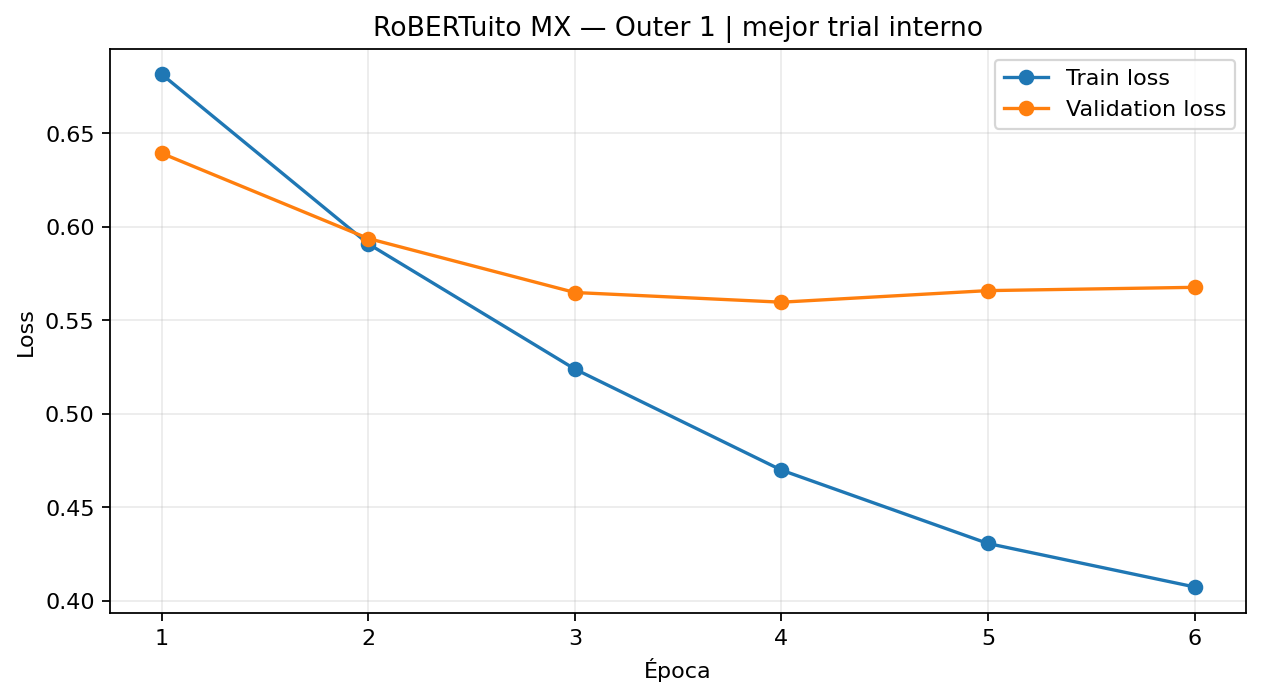

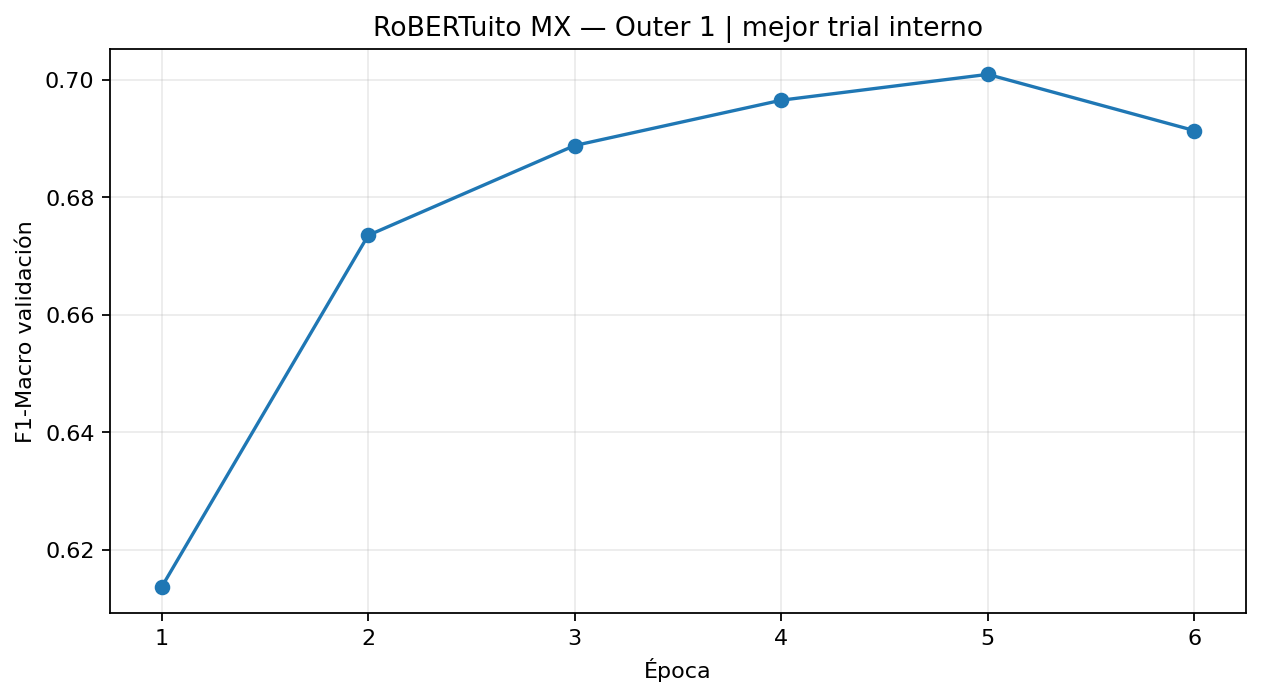

,epoch,train_loss,val_loss,train_std,val_std,val_f1_macro,n_folds
0,1.0,0.681360,0.639137,0.012910,0.037340,0.613677,3
1,2.0,0.590729,0.593597,0.015130,0.048292,0.673501,3
2,3.0,0.523800,0.564742,0.011093,0.039880,0.688784,3
3,4.0,0.469792,0.559570,0.016566,0.040388,0.696493,3
4,5.0,0.430567,0.565755,0.008614,0.046518,0.700892,3
5,6.0,0.407349,0.567509,0.019588,0.040198,0.691331,3


In [17]:
# Modifica estos dos valores para revisar las curvas del mejor trial de un fold.
VARIANTE_GRAFICA = "mx"
OUTER_GRAFICA = 1

from IPython.display import Image

ruta_loss = GRAPH_DIR / VARIANTE_GRAFICA / f"outer{OUTER_GRAFICA}_loss.png"
ruta_f1 = GRAPH_DIR / VARIANTE_GRAFICA / f"outer{OUTER_GRAFICA}_f1.png"
ruta_csv = GRAPH_DIR / VARIANTE_GRAFICA / f"outer{OUTER_GRAFICA}_media_por_epoca.csv"

if ruta_loss.exists() and ruta_f1.exists():
    print(f"[{VARIANTE_GRAFICA.upper()}][RoBERTuito][Outer {OUTER_GRAFICA}] Curvas guardadas")
    display(Image(filename=str(ruta_loss)))
    display(Image(filename=str(ruta_f1)))
    display(pd.read_csv(ruta_csv))
else:
    print("Aún no están disponibles ambas curvas para ese Outer Fold.")

## 15. Optimización final (solo train)

Se ejecuta automáticamente después de la Nested CV (`EJECUTAR_OPTIMIZACION_FINAL=True`) y solo en modo completo. Esta sección lanza 20 trials × 3 Inner Folds × 3 variantes = **180 entrenamientos adicionales**, selecciona una configuración por variante usando **solo train** y la guarda en JSON. Se hace antes de abrir el test oficial; si se interrumpe, al volver a ejecutar se reanuda desde los trials guardados.

In [18]:
def contar_completados_final():
    """Fine-tunings de la optimización final ya terminados (trials completos × 3 Inner)."""
    n = 0
    for variante in VARIANTES:
        st = cargar_study(variante, "final")
        if st is not None:
            n += (
                min(N_TRIALS, sum(t.state == optuna.trial.TrialState.COMPLETE for t in st.trials))
                * 3
            )
    return n


configs_finales = {}
if EJECUTAR_OPTIMIZACION_FINAL and MODO != "completo":
    print("Optimización final omitida en MODO='prueba' (solo se ejecuta en modo completo).")
elif EJECUTAR_OPTIMIZACION_FINAL:
    verificar_configuracion()
    # Mismo panel de seguimiento que en Nested CV: 20 trials × 3 Inner por variante.
    monitor_final = Monitor(
        RUN_DIR, total=len(VARIANTES) * N_TRIALS * 3, ya_completados=contar_completados_final()
    )
    try:
        for variante in VARIANTES:
            monitor_final.iniciar(f"{variante.upper()} | Optimización final")
            df = TRAIN_AGRUPADO[variante].copy()
            cache, y = cache_dataset(df)
            groups = df[GROUP_COL].astype(str).to_numpy()
            estudio = buscar_en_train(
                cache,
                y,
                groups,
                np.arange(len(y)),
                variante,
                "final",
                k_inner=3,
                n_trials=N_TRIALS,
                seed_cv=SEED,
                monitor=monitor_final,
            )
            cfg = estudio.best_params.copy()
            cfg["refit_epochs"] = int(estudio.best_trial.user_attrs["refit_epochs"])
            configs_finales[variante] = cfg
            print(f"{variante.upper()}: F1-CV final={estudio.best_value:.4f}; config={cfg}")
    except KeyboardInterrupt:
        monitor_final.fallar(
            "Optimización final interrumpida; los trials completos quedan en SQLite"
        )
        raise
    except Exception as exc:
        monitor_final.registrar(f"ERROR optimización final {type(exc).__name__}: {exc}")
        monitor_final.fallar(
            f"Optimización final con error {type(exc).__name__}; consultar monitor.log"
        )
        raise
    monitor_final.finalizar("Optimización final completada")
    (RESULTS_DIR / "robertuito_config_final.json").write_text(
        json.dumps(configs_finales, indent=2, ensure_ascii=False), encoding="utf-8"
    )
else:
    print("Optimización final desactivada. Analiza primero los Outer Folds.")

MX: F1-CV final=0.7097; config={'preprocessing': 'PYSENTIMIENTO', 'learning_rate': 2e-05, 'batch_size': 16, 'num_train_epochs': 6, 'weight_decay': 0.1, 'loss_mode': 'balanced', 'classifier_dropout': 0.2, 'label_smoothing': 0.1, 'lr_decay': 0.9, 'dropout_interno': 0.1, 'congelar_frac': 0.25, 'refit_epochs': 4}
ES: F1-CV final=0.7704; config={'preprocessing': 'PYSENTIMIENTO', 'learning_rate': 2e-05, 'batch_size': 16, 'num_train_epochs': 6, 'weight_decay': 0.1, 'loss_mode': 'balanced', 'classifier_dropout': 0.1, 'label_smoothing': 0.1, 'lr_decay': 0.9, 'dropout_interno': 0.1, 'congelar_frac': 0.0, 'refit_epochs': 6}
CU: F1-CV final=0.7528; config={'preprocessing': 'PYSENTIMIENTO', 'learning_rate': 2e-05, 'batch_size': 16, 'num_train_epochs': 6, 'weight_decay': 0.1, 'loss_mode': 'balanced', 'classifier_dropout': 0.1, 'label_smoothing': 0.1, 'lr_decay': 0.9, 'dropout_interno': 0.1, 'congelar_frac': 0.25, 'refit_epochs': 5}

✅ [RoBERTuito] Optimización final completada — 2026-10-26 15:32:27


## 16. Curvas de entrenamiento de la configuración final (figura del informe)

Una figura por modelo con un panel por variante (MX, ES, CU), usando la **configuración final** de cada variante:

- fila superior: pérdida de train y de validación por época;
- fila inferior: F1-Macro de validación por época;
- línea y banda: media ± desviación estándar de los 3 Inner Folds;
- marcador hueco: época que solo alcanzó un Inner Fold por el early stopping;
- línea punteada: número de épocas usado en el refit.

Se guarda en PNG (para el documento) y PDF (vectorial), junto con un CSV con los valores. No entrena nada.

**v4.** Estas curvas vienen de los Inner Folds con early stopping (pocas épocas). La figura de convergencia para el informe es la de la sección **16-bis**.

In [19]:
# ============================================================
# CURVAS DE ENTRENAMIENTO — CONFIGURACIÓN FINAL (FIGURA DEL INFORME)
# Una figura por modelo y un panel por variante:
#   fila 1 = pérdida de train y de validación;
#   fila 2 = F1-Macro de validación.
# Media ± desviación estándar de los 3 Inner Folds de la optimización final.
# Solo lee CSV ya guardados: no entrena nada.
# ============================================================
NOMBRE_MODELO = "RoBERTuito"

ruta_cfg = RESULTS_DIR / "robertuito_config_final.json"
if not configs_finales and ruta_cfg.exists():
    configs_finales = json.loads(ruta_cfg.read_text(encoding="utf-8"))
if not configs_finales:
    print("Aún no hay configuración final (se genera en la sección 15, en modo completo).")
else:
    salida_final = GRAPH_DIR / "config_final"
    salida_final.mkdir(parents=True, exist_ok=True)

    def curva_media_config_final(variante, cfg):
        """Promedia por época las curvas de los 3 Inner Folds de la configuración final."""
        cfg_busqueda = {k: v for k, v in cfg.items() if k != "refit_epochs"}
        partes = []
        for inner_fold in range(1, 4):
            ruta = rutas_inner_fit(variante, "final", cfg_busqueda, inner_fold)["curve"]
            if not ruta.exists():
                raise FileNotFoundError(f"Falta la curva del Inner Fold {inner_fold}: {ruta}")
            d = pd.read_csv(ruta)
            d["inner_fold"] = inner_fold
            partes.append(d)
        todas = pd.concat(partes, ignore_index=True)
        return todas.groupby("epoch", as_index=False).agg(
            train_loss=("train_loss", "mean"),
            train_std=("train_loss", "std"),
            val_loss=("val_loss", "mean"),
            val_std=("val_loss", "std"),
            val_f1_macro=("val_f1_macro", "mean"),
            f1_std=("val_f1_macro", "std"),
            n_folds=("inner_fold", "nunique"),
        )

    def dibujar_serie(ax, datos, col, col_std, etiqueta, estilo):
        """Línea + banda para épocas con ≥2 Inner Folds; marcador hueco si solo queda 1."""
        respaldado = datos[datos["n_folds"] >= 2]
        aislado = datos[datos["n_folds"] < 2]
        (linea,) = ax.plot(respaldado["epoch"], respaldado[col], estilo, marker="o", label=etiqueta)
        std = respaldado[col_std].fillna(0)
        ax.fill_between(
            respaldado["epoch"],
            respaldado[col] - std,
            respaldado[col] + std,
            alpha=0.15,
            color=linea.get_color(),
        )
        if not aislado.empty:
            ax.plot(
                aislado["epoch"],
                aislado[col],
                linestyle="none",
                marker="o",
                mfc="none",
                color=linea.get_color(),
            )

    variantes_fig = [v for v in ["mx", "es", "cu"] if v in configs_finales]
    fig, axes = plt.subplots(
        2,
        len(variantes_fig),
        figsize=(4.6 * len(variantes_fig), 7.4),
        sharex="col",
        sharey="row",
        squeeze=False,
    )
    tablas = []
    for j, variante in enumerate(variantes_fig):
        cfg = configs_finales[variante]
        resumen = curva_media_config_final(variante, cfg)
        resumen.insert(0, "variante", variante)
        tablas.append(resumen)
        refit = int(cfg["refit_epochs"])

        ax_loss, ax_f1 = axes[0, j], axes[1, j]
        dibujar_serie(ax_loss, resumen, "train_loss", "train_std", "Train", "-")
        dibujar_serie(ax_loss, resumen, "val_loss", "val_std", "Validación", "--")
        dibujar_serie(ax_f1, resumen, "val_f1_macro", "f1_std", "F1-Macro validación", "-")
        for ax in (ax_loss, ax_f1):
            ax.axvline(refit, color="gray", linestyle=":", linewidth=1.2, label="Épocas del refit")
            ax.grid(alpha=0.25)
            ax.set_xticks(range(1, int(resumen["epoch"].max()) + 1))
        ax_loss.set_title(f"{variante.upper()} · refit {refit} épocas")
        ax_f1.set_xlabel("Época")
        if j == 0:
            ax_loss.set_ylabel("Pérdida")
            ax_f1.set_ylabel("F1-Macro")
            ax_loss.legend(fontsize=8)
            ax_f1.legend(fontsize=8)

    fig.suptitle(
        f"{NOMBRE_MODELO} — curvas de entrenamiento de la configuración final\n"
        "(media ± d.e. de 3 Inner Folds; marcador hueco = época alcanzada por un solo fold)",
        fontsize=11,
    )
    fig.tight_layout()
    for carpeta in (salida_final, RESULTS_DIR):
        fig.savefig(carpeta / "robertuito_curvas_entrenamiento.png", dpi=200, bbox_inches="tight")
        fig.savefig(carpeta / "robertuito_curvas_entrenamiento.pdf", bbox_inches="tight")
    display(fig)
    plt.close(fig)

    df_curvas_finales = pd.concat(tablas, ignore_index=True)
    csv_atomico(df_curvas_finales, RESULTS_DIR / "robertuito_curvas_entrenamiento.csv")
    for variante in variantes_fig:
        print(f"{variante.upper()} — configuración final: {configs_finales[variante]}")
    display(df_curvas_finales.round(4))

<Figure size 1380x740 with 6 Axes>

MX — configuración final: {'preprocessing': 'PYSENTIMIENTO', 'learning_rate': 2e-05, 'batch_size': 16, 'num_train_epochs': 6, 'weight_decay': 0.1, 'loss_mode': 'balanced', 'classifier_dropout': 0.2, 'label_smoothing': 0.1, 'lr_decay': 0.9, 'dropout_interno': 0.1, 'congelar_frac': 0.25, 'refit_epochs': 4}
ES — configuración final: {'preprocessing': 'PYSENTIMIENTO', 'learning_rate': 2e-05, 'batch_size': 16, 'num_train_epochs': 6, 'weight_decay': 0.1, 'loss_mode': 'balanced', 'classifier_dropout': 0.1, 'label_smoothing': 0.1, 'lr_decay': 0.9, 'dropout_interno': 0.1, 'congelar_frac': 0.0, 'refit_epochs': 6}
CU — configuración final: {'preprocessing': 'PYSENTIMIENTO', 'learning_rate': 2e-05, 'batch_size': 16, 'num_train_epochs': 6, 'weight_decay': 0.1, 'loss_mode': 'balanced', 'classifier_dropout': 0.1, 'label_smoothing': 0.1, 'lr_decay': 0.9, 'dropout_interno': 0.1, 'congelar_frac': 0.25, 'refit_epochs': 5}


,variante,epoch,train_loss,train_std,val_loss,val_std,val_f1_macro,f1_std,n_folds
0,mx,1.0,0.6722,0.0042,0.6197,0.0071,0.6438,0.0126,3
1,mx,2.0,0.5930,0.0047,0.5728,0.0182,0.6824,0.0178,3
2,mx,3.0,0.5326,0.0053,0.5655,0.0230,0.6945,0.0202,3
3,mx,4.0,0.4883,0.0047,0.5654,0.0322,0.6966,0.0248,3
4,mx,5.0,0.4486,0.0052,0.5592,0.0185,0.7017,0.0102,3
5,mx,6.0,0.4358,0.0009,0.5525,0.0288,0.7092,0.0045,2
6,es,1.0,0.6285,0.0069,0.5255,0.0162,0.7170,0.0156,3
7,es,2.0,0.5252,0.0086,0.4823,0.0121,0.7415,0.0114,3
8,es,3.0,0.4482,0.0083,0.4603,0.0196,0.7562,0.0131,3
9,es,4.0,0.3943,0.0098,0.4550,0.0245,0.7599,0.0164,3


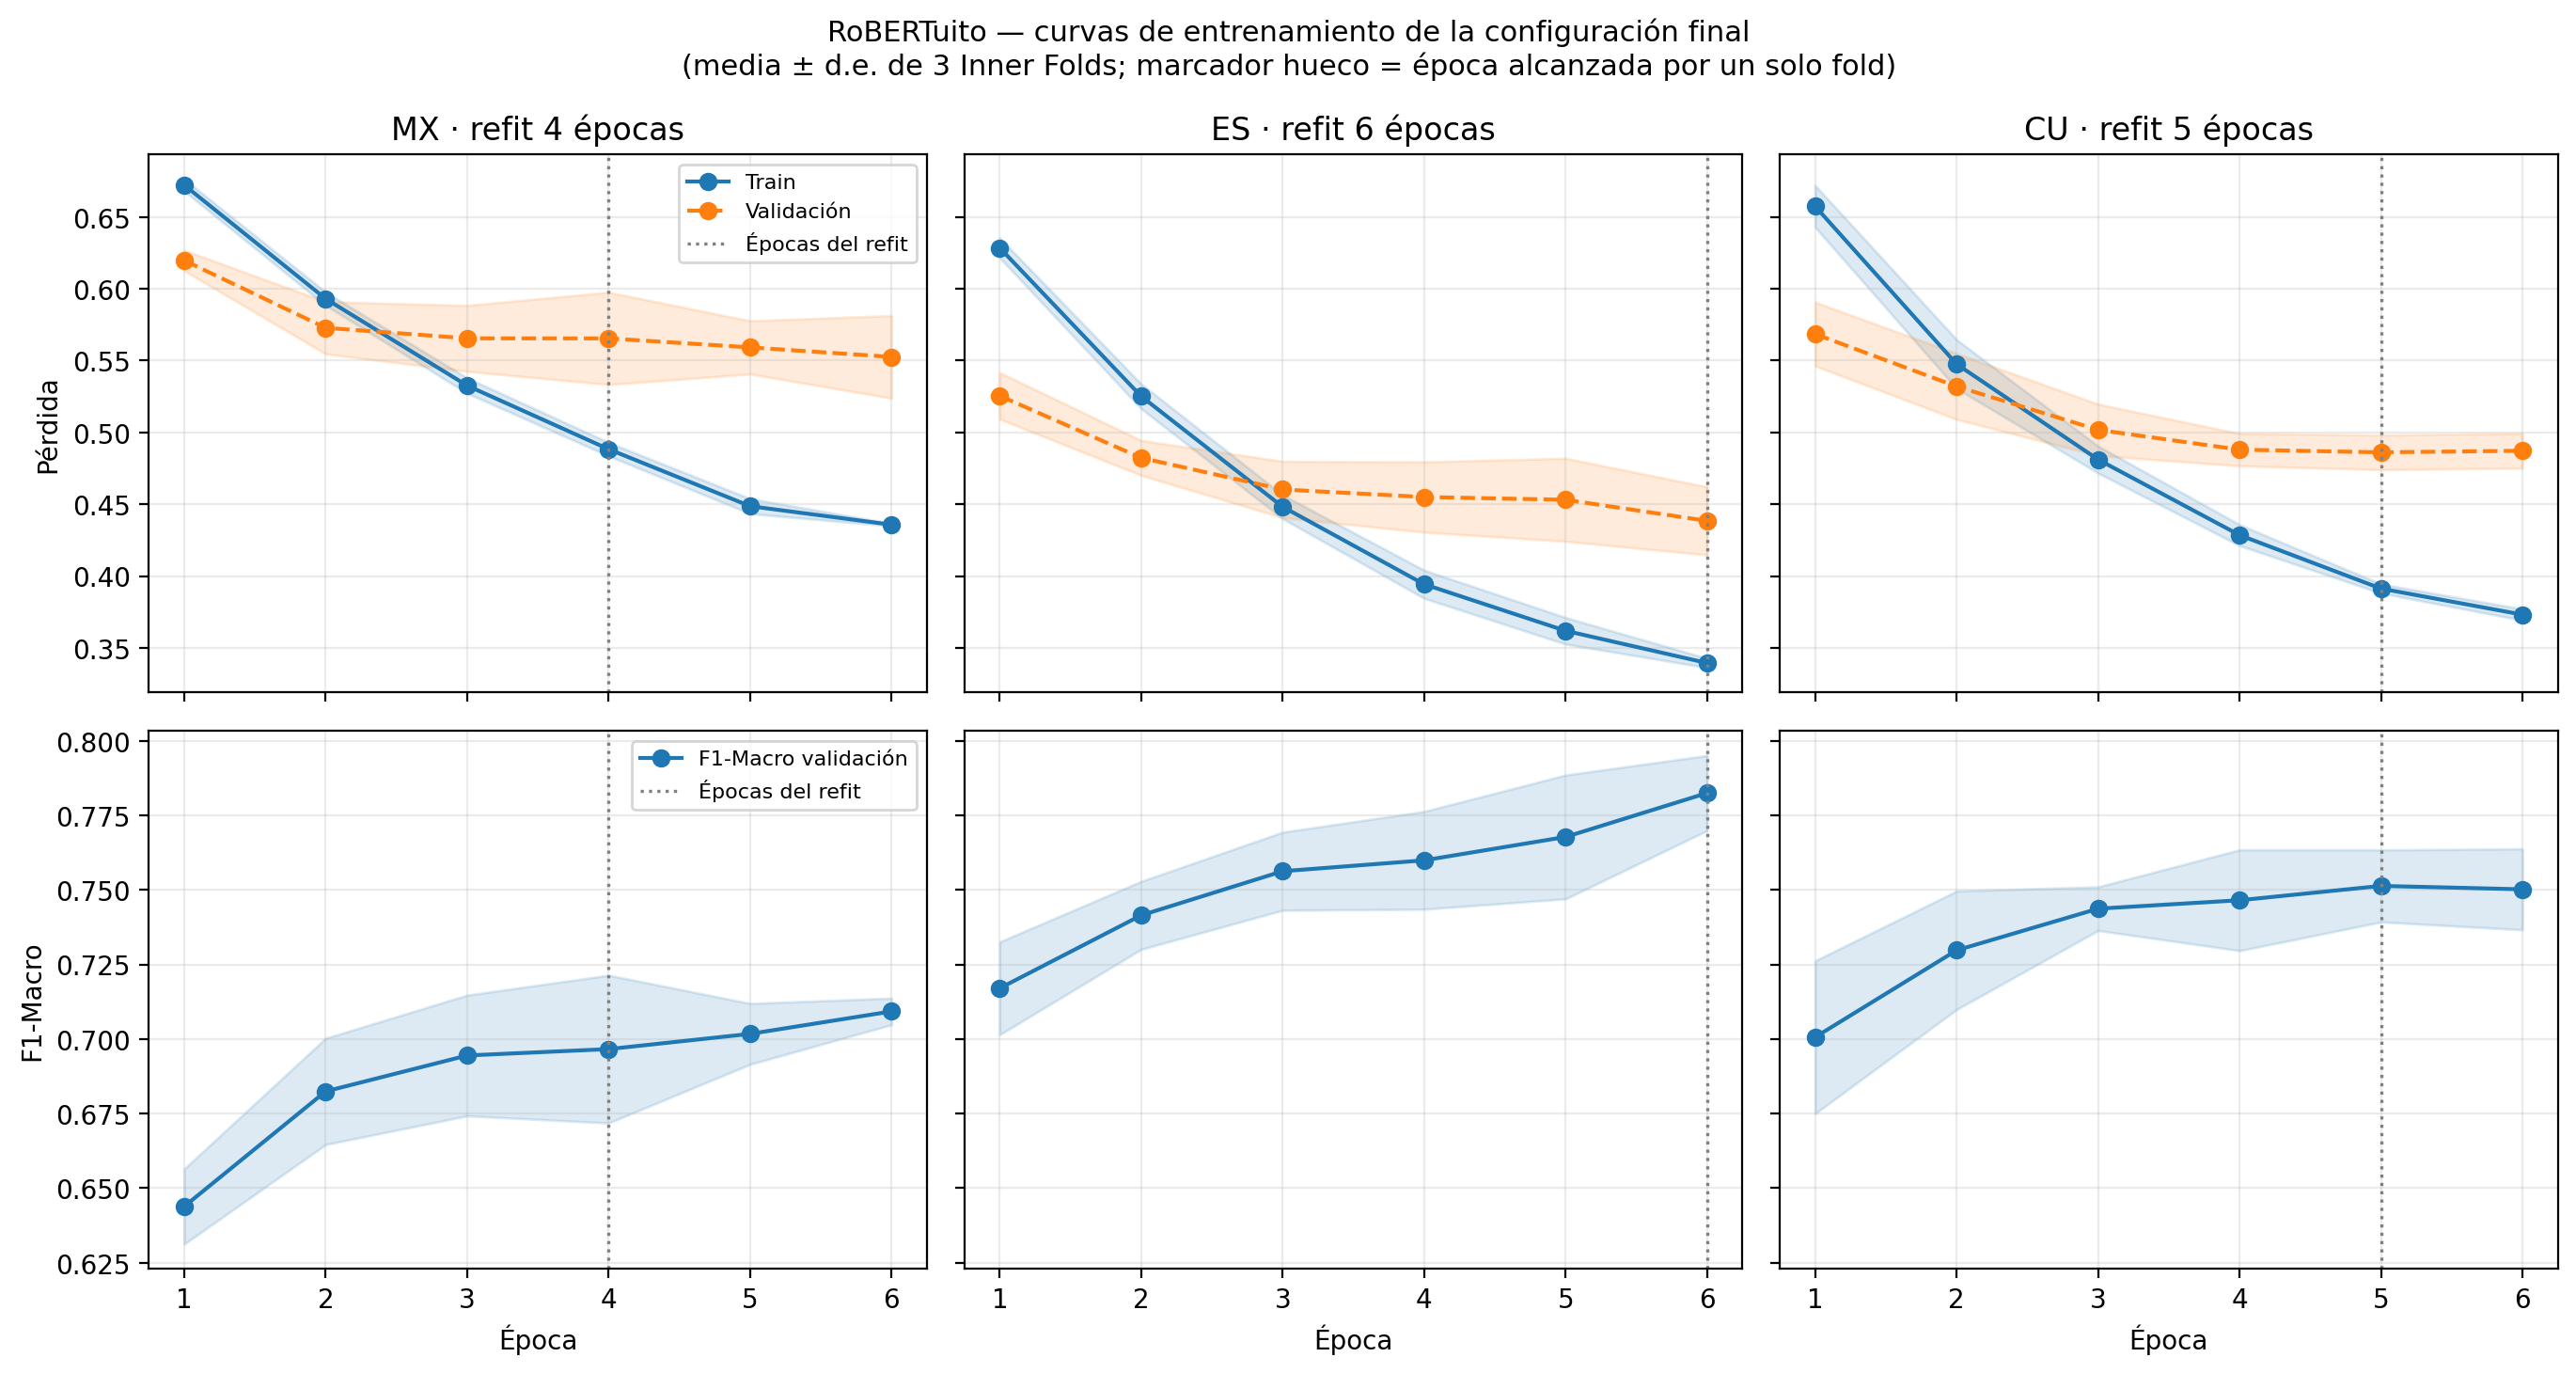

In [20]:
from IPython.display import Image

ruta_figura = RESULTS_DIR / "robertuito_curvas_entrenamiento.png"
if ruta_figura.exists():
    display(Image(filename=str(ruta_figura)))
else:
    print("Aún no se ha generado la figura: ejecuta la celda anterior tras la optimización final.")

## 16-bis. Diagnóstico de convergencia de la configuración final (figura del informe)

Reentrena la configuración final en sus **3 Inner Folds sin early stopping**, evaluando 4 veces por época y midiendo la pérdida de train y de validación de la misma forma (modo eval). La zona sombreada es posterior al refit: el modelo final no llega ahí. ~9 fine-tunings; solo train oficial. Genera `<modelo>_diagnostico_convergencia.png/.pdf/.csv` y una tabla resumen.

**v5:** el train se evalúa completo (no una submuestra), las curvas muestran la **NLL sin pesos de clase** (no la pérdida ponderada) y se guardan los logits de validación de cada Inner Fold en la época del refit. Con esas predicciones *out-of-fold* (todas del train oficial) se ajusta la **temperatura** del temperature scaling, que la sección 17 aplica a las probabilidades del test sin usar el test para ajustarla.

In [21]:
# ============================================================
# 16-bis. DIAGNÓSTICO DE CONVERGENCIA (solo train; NO selecciona nada)
# Reentrena la configuración final en sus 3 Inner Folds SIN early stopping,
# con 4 evaluaciones por época, midiendo train y validación de la misma forma.
# Es la figura de curvas para el informe. ~9 fine-tunings. No toca el test.
# PILOTO=None usa la configuración final; "A"/"B" eran los pilotos de la v3.
# ============================================================
import math

PILOTO = None
VARIANTES_PILOTO = ["mx"]
REHACER = False          # True = borra los CSV previos de este diagnóstico
EVALS_POR_EPOCA = 4
LIMITE_Y_LOSS = None     # p. ej. 1.0 para recortar el eje de pérdida

PILOTOS = {
    "A": {"learning_rate": 1e-5, "num_train_epochs": 5, "label_smoothing": 0.0, "lr_decay": 1.0},
    "B": {"learning_rate": 1e-5, "num_train_epochs": 5, "label_smoothing": 0.1, "lr_decay": 0.9},
}


def _args_diagnostico(carpeta, cfg, seed, eval_steps, epocas):
    params = dict(
        output_dir=str(carpeta),
        learning_rate=cfg["learning_rate"],
        per_device_train_batch_size=cfg["batch_size"],
        per_device_eval_batch_size=64,
        num_train_epochs=epocas,
        weight_decay=cfg["weight_decay"],
        warmup_ratio=0.10,
        optim="adamw_torch",
        logging_strategy="steps",
        logging_steps=eval_steps,
        eval_steps=eval_steps,
        save_strategy="no",
        load_best_model_at_end=False,
        report_to="none",
        disable_tqdm=True,
        dataloader_num_workers=0,
        seed=seed,
        data_seed=seed,
        bf16=USE_BF16,
        fp16=USE_FP16,
    )
    sig = inspect.signature(TrainingArguments.__init__).parameters
    params["eval_strategy" if "eval_strategy" in sig else "evaluation_strategy"] = "steps"
    return TrainingArguments(**{k: v for k, v in params.items() if k in sig})


def _historia_a_tabla(log_history, metricas_paso0, pasos_epoca):
    mapa = {
        "eval_train_loss": "train_loss",
        "eval_val_loss": "val_loss",
        "eval_train_f1_macro": "train_f1",
        "eval_val_f1_macro": "val_f1",
        "eval_train_nll": "train_nll",
        "eval_val_nll": "val_nll",
        "eval_train_ece": "train_ece",
        "eval_val_ece": "val_ece",
        "loss": "train_loss_running",
    }
    filas = {0: {"step": 0, **metricas_paso0}}
    for e in log_history:
        if "step" not in e:
            continue
        fila = filas.setdefault(e["step"], {"step": e["step"]})
        for origen, destino in mapa.items():
            if origen in e:
                fila[destino] = float(e[origen])
    tabla = pd.DataFrame(list(filas.values())).sort_values("step")
    tabla = tabla[tabla["val_loss"].notna()].reset_index(drop=True)
    tabla["epoch"] = tabla["step"] / pasos_epoca
    tabla["pasos_epoca"] = pasos_epoca
    return tabla


def diagnostico_convergencia():
    base = NOMBRE_EXPERIMENTO.lower()
    configs_diag = json.loads(
        (RESULTS_DIR / f"{base}_config_final.json").read_text(encoding="utf-8")
    )
    if PILOTO is None:
        etiqueta = f"{base}_diagnostico"
    else:
        etiqueta = f"{base}_piloto{PILOTO}"
        configs_diag = {v: {**configs_diag[v], **PILOTOS[PILOTO]} for v in VARIANTES_PILOTO}

    diag_dir = RESULTS_DIR / f"diag_{etiqueta}"
    if REHACER and diag_dir.exists():
        shutil.rmtree(diag_dir)
    diag_dir.mkdir(parents=True, exist_ok=True)

    partes = []
    for variante, cfg_full in configs_diag.items():
        cfg = {k: v for k, v in cfg_full.items() if k != "refit_epochs"}
        epocas = int(cfg["num_train_epochs"])
        df = TRAIN_AGRUPADO[variante].copy()
        cache, y = cache_dataset(df)
        ds = cache[cfg["preprocessing"]]
        groups = df[GROUP_COL].astype(str).to_numpy()
        # Mismos splits que la optimización final (k_inner=3, seed_cv=SEED).
        skf = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
        splits = list(skf.split(np.zeros(len(y)), y, groups=groups))

        for numero, (tr, val) in enumerate(splits, start=1):
            ruta_csv = diag_dir / f"{variante}_inner{numero}.csv"
            ruta_logits = diag_dir / f"{variante}_inner{numero}_logits_refit.npz"
            if ruta_csv.exists() and ruta_logits.exists():
                partes.append(pd.read_csv(ruta_csv))
                print(f"[DIAG] {variante.upper()} inner {numero}: reutilizado")
                continue

            seed_fold = SEED + SEED * 100 + numero  # misma semilla que la búsqueda final
            rng = np.random.default_rng(seed_fold)
            tr_eval = np.asarray(tr)  # v5: train COMPLETO en modo eval (auditoría)
            pasos_epoca = math.ceil(len(tr) / cfg["batch_size"])
            eval_steps = max(1, pasos_epoca // EVALS_POR_EPOCA)
            carpeta = TMP_DIR / f"diag_{variante}_in{numero}"

            model = crear_modelo(seed_fold, cfg["classifier_dropout"], cfg)
            cw = pesos_balanceados(y[tr]) if cfg["loss_mode"] == "balanced" else None
            ds_train_eval = Subset(ds, tr_eval.tolist())
            ds_val = Subset(ds, val.tolist())
            trainer = None
            registro_val = {"pasos": [], "logits": []}

            def _metricas_guardando_val(prediction, _reg=registro_val, _n=len(val)):
                logits_p = prediction[0][0] if isinstance(prediction[0], tuple) else prediction[0]
                if len(logits_p) == _n and _reg.get("trainer") is not None:
                    _reg["pasos"].append(int(_reg["trainer"].state.global_step))
                    _reg["logits"].append(np.asarray(logits_p, dtype=np.float32))
                return metricas(prediction)

            if len(tr_eval) == len(val):
                raise RuntimeError("train y validación con igual tamaño: no se distinguen los logits")
            try:
                trainer = entrenador_silencioso(
                    ClasificadorTrainer(
                        model=model,
                        args=_args_diagnostico(carpeta, cfg, seed_fold, eval_steps, epocas),
                        train_dataset=Subset(ds, tr.tolist()),
                        eval_dataset={"train": ds_train_eval, "val": ds_val},
                        data_collator=data_collator,
                        compute_metrics=_metricas_guardando_val,
                        class_weights=cw,
                        label_smoothing=cfg.get("label_smoothing", 0.0),
                        lr_decay=cfg.get("lr_decay", 1.0),
                    )
                )
                print(
                    f"[CHECK] {variante.upper()} inner {numero} | lr={cfg['learning_rate']} | "
                    f"label_smoothing={trainer.label_smoothing} | lr_decay={trainer.lr_decay} | "
                    f"pasos/época={pasos_epoca}"
                )
                registro_val["trainer"] = trainer
                m_tr = trainer.evaluate(eval_dataset=ds_train_eval, metric_key_prefix="eval_train")
                m_va = trainer.evaluate(eval_dataset=ds_val, metric_key_prefix="eval_val")
                paso0 = {
                    "train_loss": m_tr["eval_train_loss"],
                    "train_f1": m_tr["eval_train_f1_macro"],
                    "val_loss": m_va["eval_val_loss"],
                    "val_f1": m_va["eval_val_f1_macro"],
                    "train_nll": m_tr["eval_train_nll"],
                    "val_nll": m_va["eval_val_nll"],
                    "train_ece": m_tr["eval_train_ece"],
                    "val_ece": m_va["eval_val_ece"],
                }
                trainer.state.log_history = []
                trainer.train()
                tabla = _historia_a_tabla(trainer.state.log_history, paso0, pasos_epoca)
                # v5: logits out-of-fold en la época del refit -> temperature scaling (solo train).
                paso_refit = float(cfg_full.get("refit_epochs", epocas)) * pasos_epoca
                pasos_v = np.asarray(registro_val["pasos"])
                k_refit = int(np.argmin(np.abs(pasos_v - paso_refit)))
                np.savez_compressed(
                    ruta_logits, logits=registro_val["logits"][k_refit], labels=y[val],
                    val_idx=np.asarray(val), paso=pasos_v[k_refit],
                )
            finally:
                registro_val["trainer"] = None
                if trainer is not None:
                    del trainer
                del model
                liberar_memoria()
                shutil.rmtree(carpeta, ignore_errors=True)

            tabla.insert(0, "inner_fold", numero)
            tabla.insert(0, "variante", variante)
            csv_atomico(tabla, ruta_csv)
            partes.append(tabla)
            print(f"[DIAG] {variante.upper()} inner {numero}: {len(tabla)} puntos")

    # v5: temperatura ajustada con los logits out-of-fold del train (3 Inner Folds = todo el train).
    if PILOTO is None:
        temperaturas = {}
        for variante in configs_diag:
            zs, ys = [], []
            for numero in (1, 2, 3):
                datos = np.load(diag_dir / f"{variante}_inner{numero}_logits_refit.npz")
                zs.append(datos["logits"])
                ys.append(datos["labels"])
            z, yy = np.concatenate(zs), np.concatenate(ys)
            grilla = np.exp(np.linspace(np.log(0.25), np.log(8.0), 400))
            T = float(grilla[int(np.argmin([nll_binaria(softmax_np(z / g), yy) for g in grilla]))])
            temperaturas[variante] = {
                "T": T,
                "nll_oof_antes": nll_binaria(softmax_np(z), yy),
                "nll_oof_despues": nll_binaria(softmax_np(z / T), yy),
                "ece_oof_antes": ece_binaria(softmax_np(z), yy),
                "ece_oof_despues": ece_binaria(softmax_np(z / T), yy),
            }
            print(f"[TS] {variante.upper()}: T={T:.3f} | NLL OOF {temperaturas[variante]['nll_oof_antes']:.4f}"
                  f" -> {temperaturas[variante]['nll_oof_despues']:.4f} | ECE OOF "
                  f"{temperaturas[variante]['ece_oof_antes']:.4f} -> {temperaturas[variante]['ece_oof_despues']:.4f}")
        (RESULTS_DIR / f"{base}_temperatura.json").write_text(
            json.dumps(temperaturas, indent=2), encoding="utf-8"
        )

    diag = pd.concat(partes, ignore_index=True)
    diag["epoch_r"] = (diag["epoch"] * EVALS_POR_EPOCA).round() / EVALS_POR_EPOCA
    csv_atomico(diag, RESULTS_DIR / f"{etiqueta}_convergencia.csv")

    resumen = []
    for variante, d in diag.groupby("variante"):
        media = d.groupby("epoch_r", as_index=False).mean(numeric_only=True)
        i_loss, i_f1 = media["val_nll"].idxmin(), media["val_f1"].idxmax()
        resumen.append(
            {
                "variante": variante,
                "min_val_nll": media.loc[i_loss, "val_nll"],
                "epoca_min_loss": media.loc[i_loss, "epoch_r"],
                "max_val_f1": media.loc[i_f1, "val_f1"],
                "epoca_max_f1": media.loc[i_f1, "epoch_r"],
                "train_f1_en_max": media.loc[i_f1, "train_f1"],
                "brecha_f1": media.loc[i_f1, "train_f1"] - media.loc[i_f1, "val_f1"],
                "val_nll_en_max_f1": media.loc[i_f1, "val_nll"],
                "val_ece_en_max_f1": media.loc[i_f1, "val_ece"],
                "val_nll_final": media["val_nll"].iloc[-1],
                "pasos_por_epoca": int(d["pasos_epoca"].mean()),
            }
        )
    resumen = pd.DataFrame(resumen)
    csv_atomico(resumen, RESULTS_DIR / f"{etiqueta}_resumen.csv")
    display(resumen.round(4))

    variantes_fig = [v for v in ["mx", "es", "cu"] if v in configs_diag]
    fig, axes = plt.subplots(
        2, len(variantes_fig), figsize=(4.8 * len(variantes_fig), 7.6), sharex="col", squeeze=False
    )
    series = [
        ("train_nll", "Train completo (modo eval)", "C0", 0),
        ("val_nll", "Validación", "C1", 0),
        ("train_f1", "Train (modo eval)", "C0", 1),
        ("val_f1", "Validación", "C1", 1),
    ]
    for j, variante in enumerate(variantes_fig):
        d = diag[diag["variante"] == variante]
        media = d.groupby("epoch_r", as_index=False).mean(numeric_only=True)
        for col, nombre, color, fila in series:
            ax = axes[fila, j]
            for _, g in d.groupby("inner_fold"):
                ax.plot(g["epoch"], g[col], color=color, alpha=0.25, linewidth=0.9)
            ax.plot(media["epoch_r"], media[col], color=color, linewidth=2.2, label=nombre)
        run = media.dropna(subset=["train_loss_running"])
        axes[0, j].plot(
            run["epoch_r"], run["train_loss_running"], color="gray", linestyle="--",
            linewidth=1, label="Train (media durante el tramo)",
        )
        cfg_v = configs_diag[variante]
        if PILOTO is None:
            refit = float(cfg_v["refit_epochs"])
            for ax in axes[:, j]:
                ax.axvline(refit, color="k", linestyle=":", linewidth=1.1, label="Épocas del refit")
                ax.axvspan(refit, media["epoch_r"].max(), color="gray", alpha=0.08,
                           label="No usado (posterior al refit)")
            titulo = f"{variante.upper()} · refit {refit:g} épocas"
        else:
            titulo = (f"{variante.upper()} · LR {cfg_v['learning_rate']:g}"
                      f" · LS {cfg_v.get('label_smoothing', 0.0):g}"
                      f" · LRD {cfg_v.get('lr_decay', 1.0):g}")
        for ax in axes[:, j]:
            ax.grid(alpha=0.25)
        if LIMITE_Y_LOSS is not None:
            axes[0, j].set_ylim(0, LIMITE_Y_LOSS)
        axes[0, j].set_title(titulo, fontsize=10)
        axes[1, j].set_xlabel(f"Época (≈{int(d['pasos_epoca'].mean())} pasos por época)")
    axes[0, 0].set_ylabel("NLL sin pesos de clase")
    axes[1, 0].set_ylabel("F1-Macro")
    axes[0, 0].legend(fontsize=7)
    axes[1, 0].legend(fontsize=7)
    subt = "configuración final" if PILOTO is None else f"piloto {PILOTO}"
    fig.suptitle(
        f"{NOMBRE_EXPERIMENTO} — diagnóstico de convergencia ({subt})\n"
        f"(3 Inner Folds, sin early stopping, {EVALS_POR_EPOCA} evaluaciones por época; "
        "solo train oficial)",
        fontsize=10.5,
    )
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(RESULTS_DIR / f"{etiqueta}_convergencia.{ext}", dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)


if MODO != "completo":
    print("Diagnóstico omitido en MODO='prueba' (requiere la configuración final del modo completo).")
elif not (RESULTS_DIR / f"{NOMBRE_EXPERIMENTO.lower()}_config_final.json").exists():
    print("Aún no hay configuración final: termina primero la sección 15.")
else:
    diagnostico_convergencia()

[CHECK] MX inner 1 | lr=2e-05 | label_smoothing=0.1 | lr_decay=0.9 | pasos/época=100
[DIAG] MX inner 1: 25 puntos
[CHECK] MX inner 2 | lr=2e-05 | label_smoothing=0.1 | lr_decay=0.9 | pasos/época=100
[DIAG] MX inner 2: 25 puntos
[CHECK] MX inner 3 | lr=2e-05 | label_smoothing=0.1 | lr_decay=0.9 | pasos/época=100
[DIAG] MX inner 3: 25 puntos
[CHECK] ES inner 1 | lr=2e-05 | label_smoothing=0.1 | lr_decay=0.9 | pasos/época=100
[DIAG] ES inner 1: 25 puntos
[CHECK] ES inner 2 | lr=2e-05 | label_smoothing=0.1 | lr_decay=0.9 | pasos/época=100
[DIAG] ES inner 2: 25 puntos
[CHECK] ES inner 3 | lr=2e-05 | label_smoothing=0.1 | lr_decay=0.9 | pasos/época=100
[DIAG] ES inner 3: 25 puntos
[CHECK] CU inner 1 | lr=2e-05 | label_smoothing=0.1 | lr_decay=0.9 | pasos/época=100
[DIAG] CU inner 1: 25 puntos
[CHECK] CU inner 2 | lr=2e-05 | label_smoothing=0.1 | lr_decay=0.9 | pasos/época=100
[DIAG] CU inner 2: 25 puntos
[CHECK] CU inner 3 | lr=2e-05 | label_smoothing=0.1 | lr_decay=0.9 | pasos/época=100
[DI

,variante,min_val_nll,epoca_min_loss,max_val_f1,epoca_max_f1,train_f1_en_max,brecha_f1,val_nll_en_max_f1,val_ece_en_max_f1,val_nll_final,pasos_por_epoca
0,cu,0.4763,3.25,0.7505,5.00,0.9349,0.1844,0.4795,0.0423,0.4807,100
1,es,0.4409,4.50,0.7700,5.50,0.9498,0.1798,0.4474,0.0526,0.4445,100
2,mx,0.5517,4.75,0.7054,5.75,0.8945,0.1891,0.5528,0.0583,0.5528,100


<Figure size 1440x760 with 6 Axes>

## 17. Test oficial — bloqueado

No utilices los 600 tweets oficiales por variante hasta haber congelado el protocolo. Esta sección entrena 5 modelos nuevos por variante con semillas predeterminadas y reporta media ± desviación, sin seleccionar la mejor semilla según test. Se habilita únicamente con `EJECUTAR_TEST_OFICIAL=True` y `CONFIRMACION_TEST="TEST_OFICIAL_CONGELADO"`.

**Análisis de sensibilidad.** El preprocesamiento no retira del train los textos que coinciden con el test. Antes de evaluar, se marcan los textos del test que coinciden con alguno del train (mismo `MESSAGE` original o misma secuencia de tokens de entrada de RoBERTuito) y se guardan en `audit/coincidencias_test_train_<variante>_<prep>.csv`. Para cada semilla se reporta el F1-Macro con los 600 textos y, con el mismo modelo, el F1-Macro sin esos textos. Este cálculo no interviene en ninguna decisión del modelo.

Además se guardan, por semilla y por texto, la predicción y la probabilidad de ironía en `robertuito_test_probabilidades.csv`: son la base de la curva ROC, la curva Precision-Recall y las matrices de confusión del notebook de comparación final.

In [24]:
EJECUTAR_TEST_OFICIAL=True
CONFIRMACION_TEST="TEST_OFICIAL_CONGELADO"

In [25]:
def cargar_test(variante):
    ruta = DATA_DIR / f"test_transformers_{variante}.csv"
    if not ruta.exists():
        raise FileNotFoundError(ruta)
    df = pd.read_csv(ruta)
    req = [ID_COL, ORIGINAL_COL, LABEL_COL, *TEXT_COLS.values()]
    if any(col not in df.columns for col in req):
        raise ValueError(f"Test {variante} no contiene todas las columnas esperadas.")
    df[ID_COL] = df[ID_COL].astype(str)
    df[LABEL_COL] = df[LABEL_COL].astype(int)
    df[ORIGINAL_COL] = df[ORIGINAL_COL].fillna("").astype(str)
    for col in TEXT_COLS.values():
        df[col] = df[col].fillna("").astype(str)
    if len(df) != 600:
        raise ValueError(f"Se esperan 600 ejemplos del test oficial {variante}, hay {len(df)}.")
    return df.reset_index(drop=True)


def detectar_coincidencias_test(train_df, test_df, prep, variante):
    """Marca los textos del test que coinciden con alguno del train.

    Solo alimenta el análisis de sensibilidad del test oficial: no elimina
    registros ni interviene en ninguna decisión del modelo.
    Coincidencia = mismo MESSAGE original (espacios colapsados) o misma
    secuencia de tokens de entrada del modelo (truncada a MAX_LENGTH).
    """
    col = TEXT_COLS[prep]

    def claves_tokens(textos):
        ids = tokenizer(
            [str(t) for t in textos], truncation=True, max_length=MAX_LENGTH, padding=False
        )["input_ids"]
        return [tuple(x) for x in ids]

    originales_train = set(train_df[ORIGINAL_COL].map(colapsar_espacios))
    tokens_train = set(claves_tokens(train_df[col]))
    coincide_original = (
        test_df[ORIGINAL_COL].map(colapsar_espacios).isin(originales_train).to_numpy()
    )
    coincide_tokens = np.array([k in tokens_train for k in claves_tokens(test_df[col])], dtype=bool)
    mascara = coincide_original | coincide_tokens

    detalle = test_df.loc[mascara, [ID_COL, ORIGINAL_COL, col]].copy()
    detalle["coincide_original"] = coincide_original[mascara]
    detalle["coincide_tokens"] = coincide_tokens[mascara]
    csv_atomico(detalle, AUDIT_DIR / f"coincidencias_test_train_{variante}_{prep}.csv")
    return mascara


def predecir_probabilidades(trainer, dataset):
    """Probabilidades softmax por clase (columna 1 = irónico)."""
    logits = trainer.predict(dataset).predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    logits = np.asarray(logits, dtype=np.float64)
    logits = logits - logits.max(axis=1, keepdims=True)
    probs = np.exp(logits)
    return probs / probs.sum(axis=1, keepdims=True)


def evaluar_semilla_final(train_df, test_df, cfg, seed, variante, mascara_coincide, monitor=None):
    prep = cfg["preprocessing"]
    ds_train = DatasetTokenizado(train_df[TEXT_COLS[prep]], train_df[LABEL_COL])
    ds_test = DatasetTokenizado(test_df[TEXT_COLS[prep]], test_df[LABEL_COL])
    y_train = train_df[LABEL_COL].to_numpy(dtype=int)
    y_test = test_df[LABEL_COL].to_numpy(dtype=int)
    sin_coincidencias = ~np.asarray(mascara_coincide, dtype=bool)
    carpeta = CHECKPOINT_DIR / variante / "test_final" / f"seed{seed}"
    carpeta.mkdir(parents=True, exist_ok=True)
    resultado_file = FIT_STATE_DIR / f"{variante}_test_seed{seed}_complete.json"
    cfg_id = config_id(cfg)
    claves = (
        "seed",
        "f1_macro",
        "accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro_sin_coincidencias",
        "n_coincidencias",
        "nll",
        "ece",
        "nll_calibrada",
        "ece_calibrada",
        "temperatura",
    )
    pred_file = FIT_STATE_DIR / f"{variante}_test_seed{seed}_predicciones.csv"
    if resultado_file.exists():
        if not pred_file.exists():
            raise FileNotFoundError(
                f"Falta {pred_file}; borra {resultado_file} y repite esa semilla."
            )
        previo = json.loads(resultado_file.read_text(encoding="utf-8"))
        if previo.get("config_id") != cfg_id:
            raise ValueError("Configuración final distinta a la guardada para la semilla")
        return {k: previo.get(k) for k in claves}
    if monitor:
        monitor.iniciar(f"{variante.upper()} | Test oficial | semilla {seed}")
    cw = pesos_balanceados(y_train) if cfg["loss_mode"] == "balanced" else None
    model = crear_modelo(seed, cfg["classifier_dropout"], cfg)
    trainer = None
    try:
        args = argumentos_entrenamiento(
            carpeta, cfg, seed, con_validacion=False, epochs=cfg["num_train_epochs"]
        )
        trainer = entrenador_silencioso(
            ClasificadorTrainer(
                model=model,
                args=args,
                train_dataset=ds_train,
                data_collator=data_collator,
                class_weights=cw,
                label_smoothing=cfg["label_smoothing"],
                lr_decay=cfg["lr_decay"],
                callbacks=[DetenerEnEpoca(cfg["refit_epochs"])]
                + ([PulsoTrainer(monitor)] if monitor else []),
            )
        )
        ultimo = get_last_checkpoint(str(carpeta))
        trainer.train(resume_from_checkpoint=ultimo if ultimo else None)
        probs = predecir_probabilidades(trainer, ds_test)
        y_pred = probs.argmax(axis=1)
        # v5: temperatura ajustada SOLO con predicciones out-of-fold del train (sección 16-bis).
        ruta_T = RESULTS_DIR / f"{NOMBRE_EXPERIMENTO.lower()}_temperatura.json"
        T = json.loads(ruta_T.read_text(encoding="utf-8"))[variante]["T"] if ruta_T.exists() else 1.0
        probs_cal = softmax_np(np.log(np.clip(probs, 1e-12, 1.0)) / T)
        # Predicciones y probabilidades por texto: base de la ROC, la curva PR
        # y las matrices de confusión del notebook de comparación final.
        csv_atomico(
            pd.DataFrame(
                {
                    "variante": variante,
                    "seed": int(seed),
                    "ID": test_df[ID_COL].astype(str).to_numpy(),
                    "y_true": y_test,
                    "y_pred": y_pred,
                    "prob_ironia": probs[:, 1],
                    "prob_ironia_calibrada": probs_cal[:, 1],
                    "coincide_train": ~sin_coincidencias,
                }
            ),
            pred_file,
        )
        curva = extraer_curva(trainer.state.log_history)
        if not curva.empty:
            csv_atomico(curva, CURVE_DIR / f"{variante}_test_seed{seed}.csv")
        resultado = {
            "seed": int(seed),
            "f1_macro": float(f1_score(y_test, y_pred, average="macro")),
            "accuracy": float(accuracy_score(y_test, y_pred)),
            "precision_macro": float(
                precision_score(y_test, y_pred, average="macro", zero_division=0)
            ),
            "recall_macro": float(recall_score(y_test, y_pred, average="macro", zero_division=0)),
            # Análisis de sensibilidad: mismo modelo, sin los textos que coinciden con el train.
            "f1_macro_sin_coincidencias": float(
                f1_score(y_test[sin_coincidencias], y_pred[sin_coincidencias], average="macro")
            ),
            "n_coincidencias": int((~sin_coincidencias).sum()),
            "nll": nll_binaria(probs, y_test),
            "ece": ece_binaria(probs, y_test),
            "nll_calibrada": nll_binaria(probs_cal, y_test),
            "ece_calibrada": ece_binaria(probs_cal, y_test),
            "temperatura": float(T),
        }
        json_atomico({"config_id": cfg_id, **resultado}, resultado_file)
        limpiar_checkpoint_dir(carpeta)
    finally:
        if trainer is not None:
            del trainer
        del model
        liberar_memoria()
    if monitor:
        monitor.fit_terminado(
            f"{variante.upper()} test semilla {seed}: F1={resultado['f1_macro']:.4f}"
        )
    return resultado

In [26]:
if EJECUTAR_TEST_OFICIAL:
    if MODO != "completo" or not EJECUTAR_OPTIMIZACION_FINAL:
        raise ValueError("Primero termina Nested CV y la optimización final en modo completo.")
    if CONFIRMACION_TEST != "TEST_OFICIAL_CONGELADO":
        raise ValueError("Bloqueado: confirma explícitamente la evaluación final.")
    datos_test = []
    monitor_test = Monitor(
        RUN_DIR,
        total=len(VARIANTES) * len(SEMILLAS_FINALES),
        ya_completados=sum(
            (FIT_STATE_DIR / f"{v}_test_seed{s}_complete.json").exists()
            for v in VARIANTES
            for s in SEMILLAS_FINALES
        ),
    )
    try:
        for variante in VARIANTES:
            df_train = cargar_train(variante)
            df_test = cargar_test(variante)
            cfg = configs_finales[variante]
            mascara = detectar_coincidencias_test(df_train, df_test, cfg["preprocessing"], variante)
            print(
                f"[TEST][RoBERTuito][{variante.upper()}] textos del test que coinciden "
                f"con el train: {int(mascara.sum())}/{len(mascara)}"
            )
            for seed in SEMILLAS_FINALES:
                res = evaluar_semilla_final(
                    df_train, df_test, cfg, seed, variante, mascara, monitor=monitor_test
                )
                res["variante"] = variante
                datos_test.append(res)
                print(
                    f"{variante.upper()} seed {seed}: F1={res['f1_macro']:.4f} | "
                    f"F1 sin coincidencias={res['f1_macro_sin_coincidencias']:.4f}"
                )
                csv_atomico(
                    pd.DataFrame(datos_test), RESULTS_DIR / "robertuito_test_5_semillas.csv"
                )
    except KeyboardInterrupt:
        monitor_test.fallar("Test oficial interrumpido; las semillas terminadas quedan guardadas")
        raise
    except Exception as exc:
        monitor_test.registrar(f"ERROR test oficial {type(exc).__name__}: {exc}")
        monitor_test.fallar(f"Test oficial con error {type(exc).__name__}; consultar monitor.log")
        raise
    monitor_test.finalizar("Test oficial completado (5 semillas por variante)")
    df_test_final = pd.DataFrame(datos_test)
    resumen = (
        df_test_final.groupby("variante")
        .agg(
            f1_mean=("f1_macro", "mean"),
            f1_std=("f1_macro", "std"),
            f1_sin_coincidencias_mean=("f1_macro_sin_coincidencias", "mean"),
            f1_sin_coincidencias_std=("f1_macro_sin_coincidencias", "std"),
            n_coincidencias=("n_coincidencias", "first"),
            nll_mean=("nll", "mean"),
            ece_mean=("ece", "mean"),
            nll_calibrada_mean=("nll_calibrada", "mean"),
            ece_calibrada_mean=("ece_calibrada", "mean"),
            temperatura=("temperatura", "first"),
        )
        .reset_index()
    )
    display(resumen)
    probabilidades_test = pd.concat(
        [
            pd.read_csv(FIT_STATE_DIR / f"{v}_test_seed{s}_predicciones.csv", dtype={"ID": str})
            for v in VARIANTES
            for s in SEMILLAS_FINALES
        ],
        ignore_index=True,
    )
    csv_atomico(probabilidades_test, RESULTS_DIR / "robertuito_test_probabilidades.csv")
    print(
        "Probabilidades del test guardadas en:", RESULTS_DIR / "robertuito_test_probabilidades.csv"
    )
    csv_atomico(resumen, RESULTS_DIR / "robertuito_test_resumen.csv")
else:
    print("TEST OFICIAL BLOQUEADO; no se han cargado archivos de test.")

[TEST][RoBERTuito][MX] textos del test que coinciden con el train: 2/600
MX seed 42: F1=0.7782 | F1 sin coincidencias=0.7795
MX seed 52: F1=0.7640 | F1 sin coincidencias=0.7651
MX seed 62: F1=0.7608 | F1 sin coincidencias=0.7619
MX seed 72: F1=0.7655 | F1 sin coincidencias=0.7666
MX seed 82: F1=0.7544 | F1 sin coincidencias=0.7555
[TEST][RoBERTuito][ES] textos del test que coinciden con el train: 23/600
ES seed 42: F1=0.7535 | F1 sin coincidencias=0.7476
ES seed 52: F1=0.7565 | F1 sin coincidencias=0.7508
ES seed 62: F1=0.7553 | F1 sin coincidencias=0.7497
ES seed 72: F1=0.7515 | F1 sin coincidencias=0.7455
ES seed 82: F1=0.7616 | F1 sin coincidencias=0.7562
[TEST][RoBERTuito][CU] textos del test que coinciden con el train: 1/600
CU seed 42: F1=0.7256 | F1 sin coincidencias=0.7253
CU seed 52: F1=0.7342 | F1 sin coincidencias=0.7340
CU seed 62: F1=0.7430 | F1 sin coincidencias=0.7428
CU seed 72: F1=0.7430 | F1 sin coincidencias=0.7428
CU seed 82: F1=0.7537 | F1 sin coincidencias=0.7535


,variante,f1_mean,f1_std,f1_sin_coincidencias_mean,f1_sin_coincidencias_std,n_coincidencias,nll_mean,ece_mean,nll_calibrada_mean,ece_calibrada_mean,temperatura
0,cu,0.739910,0.010591,0.739693,0.010596,1,0.505248,0.061458,0.491972,0.043447,1.193864
1,es,0.755655,0.003814,0.749947,0.004035,23,0.468204,0.070603,0.453912,0.050446,1.225383
2,mx,0.764590,0.008739,0.765729,0.008800,2,0.464408,0.034059,0.469740,0.048424,1.246857


Probabilidades del test guardadas en: ..\data\resultados_robertuito_grouped_5x3_tpe20_v5\robertuito_test_probabilidades.csv


## 18. Resumen y lista de verificación

1. Ejecutar primero `01_preprocesamiento_dl_transformers.ipynb`.
2. Confirmar que `manifest_preprocesamiento_transformers.csv` existe (versión `transformers_comun_v2`) y que `MESSAGE_TRANSFORMER` contiene texto.
3. **v4: el notebook viene con `MODO="prueba"`.** Ejecutar Run All una vez para comprobar el entorno (la optimización final, el diagnóstico y el test se omiten).
4. Verificar `PRE-FLIGHT DE DATOS: OK`.
5. RoBERTuito no retira registros del train en función del test.
6. `GROUP_ID` debe construirse con el texto original, cada representación de entrada y su secuencia tokenizada.
7. Los grupos con etiquetas mixtas se documentan, pero no se separan entre folds.
8. Para la corrida definitiva, reiniciar kernel, usar `MODO="completo"` y confirmar **5 Outer × 3 Inner × 20 trials**.
9. Nested CV y optimización final corren seguidas (solo train). El test oficial queda bloqueado hasta poner `EJECUTAR_TEST_OFICIAL=True` y `CONFIRMACION_TEST="TEST_OFICIAL_CONGELADO"`.
10. Observar el panel de progreso y `monitor.log`; los checkpoints permiten reanudar una interrupción.
11. Al finalizar, recopilar resultados por Outer Fold, resumen Nested CV, trials de Optuna y curvas.

Con el modo completo, el máximo teórico es:

`3 × 5 × (20 × 3 + 1) = 915 fine-tunings`.

**v4.** Tras la optimización final, ejecutar la sección **16-bis** (diagnóstico de convergencia, ~9 fine-tunings): su figura es la que va al informe. El test oficial sigue bloqueado hasta confirmarlo explícitamente.